# 16 · 방향마다 질량이 다르면 로봇은 어느 쪽으로 비켜 가는가

> 같은 팔이라도 어느 방향으로 미느냐에 따라 유효질량이 다르다. 그 질량으로 η를 방향마다 바꾸면, 로봇이 어느 쪽으로 돌아가고 얼마나 떨어지는지가 질량으로 정해질까?

| | |
|---|---|
| **이 노트의 질문** | 충돌 방향에 따라 유효질량이 다를 때 η(u)를 방향별로 바꾸면, 로봇은 어느 쪽으로 돌아가고 양쪽의 이격은 어떻게 달라지는가. 환산질량을 쓰면 그 차이가 어떻게 줄어드는가 |
| **최종 목표** | 방향별 η(u)가 "어느 쪽으로 피할지"와 "얼마나 떨어질지"를 동시에 정할 수 있다는 것, 그리고 그것이 실제로 정하는지는 그 분절의 비용이 경로에서 켜지는지에 달렸다는 것을 설명할 수 있다. 환산질량이 사람 쪽 질량 대비를 압축한다(팔 4배 → 1.88배)는 것을 수치로 설명할 수 있다 |
| **연구의 어느 결정과 연결되는가** | 조합 1(방향별 환산질량 → 활성 거리)의 핵심 |
| **이 노트에서 바꾸는 요인** | η를 정하는 질량: (i) 균일 / (ii) 방향별 사람 쪽 유효질량 m_h(u) / (iii) 방향별 환산질량 μ(u). 사람은 서 있고(기준 자세), 비용은 15의 결론대로 η 스케일링(w = 100 고정) |

**지금 위치:** 01~13 기초·MPPI·프로젝트 → 14 움직이는 사람 → 15 η와 w → **16 방향별 질량** → 17 ESS → 18 비용 불연속과 떨림 → 19 필요 이격 거리 → 20 안전 필터 → 21 지연 → 22 cuRobo 확인

**필요한 것:** [11](11_hand_cost_mass.ipynb) 유효질량, [14](14_moving_obstacle.ipynb) 공통 장면, [15](15_eta_vs_weight.ipynb) η 스케일링 · **예상 시간:** 45분

## 복습 퀴즈

<details><summary>1. 15에서 "질량이 클수록 더 멀리"를 원할 때 질량을 넣기로 한 자리는? (a) η (b) w</summary>

**(a)** η. w에 넣으면 이격은 η 아래에서 포화하고, 가벼운 쪽의 비용 언덕이 낮아져 뚫고 지나가는 실패가 생길 수 있었다.
</details>

<details><summary>2. 15의 η 스케일링에서 μ_ref = 4.444 kg(몸통), η0 = 0.10 m, p = 1이면 μ = 1.875 kg의 η는?</summary>

0.10 × 1.875 / 4.444 = **0.042 m**
</details>

<details><summary>3. 14의 공통 장면에서 사람은 위아래 모양이 대칭이다. 질량을 쓰지 않으면 로봇이 위로 돌지 아래로 돌지는 무엇이 정했나?</summary>

**seed**(샘플 잡음). 대칭이라 비용으로는 어느 쪽도 더 싸지 않다.
</details>

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # 노트 폴더 (common14 패키지)
import numpy as np
from functools import partial
from common14 import *
from common14 import scene as S
plt = setup_plot()

ex, ey = np.array([1.0, 0.0]), np.array([0.0, 1.0])
rows = [('팔 길이 방향 (경계, 잠기지 않음)', ex, 'arm'),
        ('팔 길이 방향 (경계 바로 아래 → 잠금)', np.array([1.0, 1e-6]) / np.hypot(1.0, 1e-6), 'arm'),
        ('팔 수직, 로봇이 위 (u = −y, 자유)', -ey, 'arm'),
        ('팔 수직, 로봇이 아래 (u = +y, 잠금)', ey, 'arm'),
        ('몸통 x 방향', ex, 'torso'),
        ('몸통 y 방향', ey, 'torso')]
print('%-34s | %-8s | %-8s' % ('충돌 방향 u (로봇 → 분절 무게중심)', 'm_h [kg]', 'μ [kg]'))
for name, u, seg in rows:
    mh = float(directional_mass(u, seg))
    print('%-34s | %-8.2f | %-8.3f' % (name, mh, reduced_mass(mh)))

충돌 방향 u (로봇 → 분절 무게중심)             | m_h [kg] | μ [kg]  
팔 길이 방향 (경계, 잠기지 않음)               | 1.00     | 0.833   
팔 길이 방향 (경계 바로 아래 → 잠금)            | 4.00     | 2.222   
팔 수직, 로봇이 위 (u = −y, 자유)           | 3.00     | 1.875   
팔 수직, 로봇이 아래 (u = +y, 잠금)          | 12.00    | 3.529   
몸통 x 방향                            | 40.00    | 4.444   
몸통 y 방향                            | 32.00    | 4.324   


## 1. 문제 — 같은 팔이라도 미는 방향에 따라 질량이 다르다

### 문제
회차 0에서 정한 팔의 유효질량은 방향에 따라 다르다(관성 행렬은 주어진 값으로만 쓴다).
- 팔 길이 방향으로 밀면 가볍고(1 kg), 팔에 수직으로 밀면 무겁다(3 kg).
- 로봇이 팔 **아래에서 위로** 밀면(u = +y) 관절이 ROM 끝에 걸려 4배(수직 12 kg)가 된다. **위에서 아래로** 밀면(u = −y) 잠기지 않는다(3 kg).

충돌 방향 u는 공통 모듈의 정의 그대로 "로봇 점 → 가장 가까운 분절의 무게중심" 단위벡터다. 로봇이 팔 위에 있으면 u는 아래(−y)를 향하고, 아래에 있으면 위(+y)를 향한다.

15의 결론대로 질량은 η에 넣는다. 이번에는 사람 전체에 질량 하나가 아니라, **방향 u마다** 그 방향의 질량으로 η(u)를 정한다. 그러면 무거운 쪽(팔 아래)은 η가 크고 가벼운 쪽(팔 위)은 η가 작다.

### 어떤 질량을 쓸까 — 사람 쪽 질량 m_h vs 환산질량 μ
11과 15에서 본 것처럼 충돌의 세기를 정하는 것은 환산질량 $\mu = m_h m_r/(m_h + m_r)$이다($m_r$ = 5 kg). μ는 $m_r$을 넘지 못하므로 무거운 쪽일수록 덜 커진다. 그래서 **대비가 압축**된다.

In [2]:
pairs = [('팔 수직: 잠금(12 kg) / 자유(3 kg)', directional_mass(ey, 'arm'), directional_mass(-ey, 'arm')),
         ('몸통 x(40 kg) / 팔 수직 자유(3 kg)', directional_mass(ex, 'torso'), directional_mass(-ey, 'arm')),
         ('팔 길이: 잠금(4 kg) / 자유(1 kg)', directional_mass(rows[1][1], 'arm'), directional_mass(ex, 'arm'))]
print('%-34s | %-10s | %-10s' % ('대비', 'm_h 비', 'μ 비'))
for name, a, b in pairs:
    print('%-34s | %-10.2f | %-10.2f' % (name, a / b, reduced_mass(a) / reduced_mass(b)))

대비                                 | m_h 비      | μ 비       
팔 수직: 잠금(12 kg) / 자유(3 kg)         | 4.00       | 1.88      
몸통 x(40 kg) / 팔 수직 자유(3 kg)        | 13.33      | 2.37      
팔 길이: 잠금(4 kg) / 자유(1 kg)          | 4.00       | 2.67      


팔의 잠금/자유 대비는 m_h로 4배인데 μ로는 1.88배다. 몸통과 팔의 대비는 13.3배 → 2.37배로 더 크게 줄어든다. 무거울수록 $\mu \to m_r$로 포화하기 때문이다.

## 2. 방향별 η 만들기 — 세 경우와 기준 맞추기

$$\eta(\mathbf{u}) = \eta_L \left(\frac{m(\mathbf{u})}{m_L}\right)^p$$

- (ii)는 $m = m_h(\mathbf{u})$, (iii)는 $m = \mu(\mathbf{u})$를 쓴다.
- **기준 맞추기:** $m_L$은 각 경우의 "가벼운 쪽"(팔 수직, 잠금 아닌 쪽 = 로봇이 팔 위에 있을 때) 질량이다. (ii)는 $m_L$ = 3 kg, (iii)는 $m_L$ = 1.875 kg. 그러면 가벼운 쪽에서 두 경우 모두 η = $\eta_L$이고, 두 경우는 **대비(무거운 쪽 / 가벼운 쪽)만 다르다**.
- $\eta_L$은 15의 η 스케일링(μ_ref = 몸통, η0 = 0.10 m)에서 μ = 1.875 kg에 해당하는 값으로 둔다(p = 1에서 0.0422 m). 그러면 (iii)는 15의 규칙을 방향별로 쓴 것과 같고, 몸통 정면에서 η = 0.10 m로 (i)과 같다.
- (i) 균일 η는 15의 몸통 기준 η = 0.10 m, 방향과 무관.

In [3]:
MU_REF = float(reduced_mass(directional_mass(ex, 'torso')))   # 15의 기준 (몸통)
M_L = {'ii': float(directional_mass(-ey, 'arm')), 'iii': float(reduced_mass(directional_mass(-ey, 'arm')))}
REDUCED = {'ii': False, 'iii': True}

def eta_L(p):
    return S.ETA0 * (M_L['iii'] / MU_REF) ** p

def eta_of_mass(case, p):
    # (ii)/(iii)의 질량 → η 함수
    return lambda m: eta_L(p) * (np.asarray(m) / M_L[case]) ** p

def case_cost(case, p=1):
    if case == 'i':
        return partial(human_cost_uniform, eta=S.ETA0, w=S.W_HUMAN)
    return partial(human_cost_directional, eta_of_mass=eta_of_mass(case, p), reduced=REDUCED[case])

print('기준: 가벼운 쪽(팔 수직 자유) η_L = %.4f m (p = 1), %.4f m (p = 1/2)\n' % (eta_L(1), eta_L(0.5)))
print('%-34s | %-6s | %-12s | %-12s | %-12s | %-12s' % ('충돌 방향', '(i)', '(ii) p=1', '(iii) p=1', '(ii) p=1/2', '(iii) p=1/2'))
for name, u, seg in rows:
    mh = float(directional_mass(u, seg))
    vals = [eta_of_mass(c, p)(reduced_mass(mh) if REDUCED[c] else mh) for p in (1, 0.5) for c in ('ii', 'iii')]
    print('%-34s | %-6.3f | %-12.4f | %-12.4f | %-12.4f | %-12.4f' % (name, S.ETA0, vals[0], vals[1], vals[2], vals[3]))

기준: 가벼운 쪽(팔 수직 자유) η_L = 0.0422 m (p = 1), 0.0650 m (p = 1/2)

충돌 방향                              | (i)    | (ii) p=1     | (iii) p=1    | (ii) p=1/2   | (iii) p=1/2 
팔 길이 방향 (경계, 잠기지 않음)               | 0.100  | 0.0141       | 0.0188       | 0.0375       | 0.0433      
팔 길이 방향 (경계 바로 아래 → 잠금)            | 0.100  | 0.0563       | 0.0500       | 0.0750       | 0.0707      
팔 수직, 로봇이 위 (u = −y, 자유)           | 0.100  | 0.0422       | 0.0422       | 0.0650       | 0.0650      
팔 수직, 로봇이 아래 (u = +y, 잠금)          | 0.100  | 0.1688       | 0.0794       | 0.1299       | 0.0891      
몸통 x 방향                            | 0.100  | 0.5625       | 0.1000       | 0.2372       | 0.1000      
몸통 y 방향                            | 0.100  | 0.4500       | 0.0973       | 0.2121       | 0.0986      


표에서 볼 것:
- 팔 수직 잠금/자유 η 비는 (ii) 4배(0.169 / 0.042 m), (iii) 1.88배(0.079 / 0.042 m)다.
- **(ii)는 몸통 η가 0.45~0.56 m로 매우 크다.** 몸통 m_h(32~40 kg)가 팔 자유(3 kg)의 11~13배이기 때문이다. 목표 (2.0, 0)은 몸통 표면에서 0.45 m 떨어져 있어서, (ii)에서는 목표가 몸통의 η 범위 안에 들어간다. 로봇은 목표에 0.05 m 안으로 들어가지 못하고 그보다 조금 뒤에서 멈출 것이다(아래 도달 시간에서 확인). 가벼운 쪽 η를 맞춘 결과이며, 이 노트에서는 그대로 둔다.
- 팔 길이 방향은 가장 가볍다. 로봇이 팔 끝을 정면에서 볼 때(출발 직후) u는 팔 길이 방향이라 팔의 η가 가장 작다. 그 근처에서 로봇이 경로 위/아래로 조금만 움직여도 잠금 여부가 바뀌어 η가 뛴다(6절에서 기록만 한다).

아래 극좌표는 왼쪽 둘이 회차 0의 방향-질량(m_h, μ), 오른쪽 둘이 (ii)와 (iii)의 방향-η(p = 1)다. 각도 θ는 u의 방향이다. θ = 90°는 u가 위를 향함 = 로봇이 팔 **아래**에 있음(잠금).

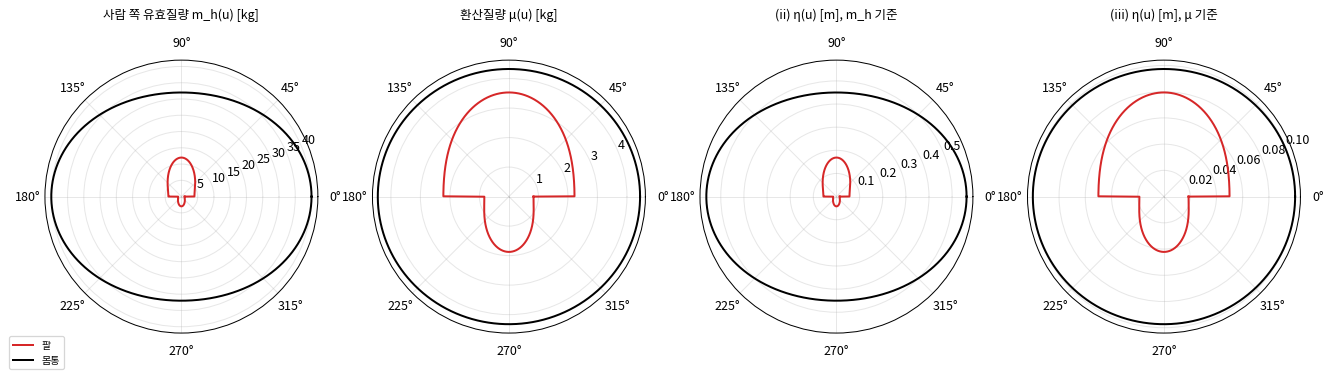

In [4]:
th = np.linspace(0, 2 * np.pi, 1441)
U_dir = np.stack([np.cos(th), np.sin(th)], -1)
fig, axs = plt.subplots(1, 4, figsize=(18, 4.6), subplot_kw=dict(projection='polar'))
for ax, title, fn in [
        (axs[0], '사람 쪽 유효질량 m_h(u) [kg]', lambda seg: directional_mass(U_dir, seg)),
        (axs[1], '환산질량 μ(u) [kg]', lambda seg: reduced_mass(directional_mass(U_dir, seg))),
        (axs[2], '(ii) η(u) [m], m_h 기준', lambda seg: eta_of_mass('ii', 1)(directional_mass(U_dir, seg))),
        (axs[3], '(iii) η(u) [m], μ 기준', lambda seg: eta_of_mass('iii', 1)(reduced_mass(directional_mass(U_dir, seg))))]:
    for seg, col in [('arm', 'C3'), ('torso', 'k')]:
        ax.plot(th, fn(seg), color=col, lw=1.6, label='팔' if seg == 'arm' else '몸통')
    ax.set_title(title, fontsize=10, pad=14)
axs[0].legend(fontsize=8, loc='lower left', bbox_to_anchor=(-0.15, -0.15))
plt.show()

**읽는 법:** 팔(빨강)은 위쪽 반(θ = 0~180°, 로봇이 아래 = 잠금)이 아래쪽 반보다 크다. m_h에서는 4배 차이인데 μ에서는 그 차이가 줄었다. (ii)의 η에서는 몸통(검정)이 팔보다 훨씬 커서 팔이 원점 근처에 작게 보인다. (iii)에서는 몸통과 팔의 차이도 작다.

**예측해 보기:** (ii)와 (iii)에서 로봇은 팔 위(가벼운 쪽, η 작음)와 아래(무거운 쪽, η 큼) 중 어느 쪽으로 더 자주 지나갈까? (i)에서는?

## 3. 방향 선택 — seed 32개

14의 기본 장면(사람 정지, 목표 (2.0, 0))에서 (i), (ii), (iii)을 seed 32개씩 돌린다. p = 1/2은 (ii), (iii)을 한 줄씩 추가한다. 로봇이 몸통 중심의 x(1.35 m)를 지날 때 y > 0이면 "위"(가벼운 쪽), y < 0이면 "아래"(무거운 쪽)로 센다.

In [5]:
SEEDS = range(32)
CASES = [('i', 1), ('ii', 1), ('iii', 1), ('ii', 0.5), ('iii', 0.5)]

def side_of(traj):
    k = np.nonzero(traj[:, 0] >= S.TORSO_C[0])[0]
    return None if len(k) == 0 else ('위' if traj[k[0], 1] > 0 else '아래')

def run_case(cost, seed):
    r = run_mpc(static_person, human_cost=cost, seed=seed)
    tr = r['traj']
    segg = segment_gaps(tr)                                  # [N+1, 2]: torso, arm
    return dict(traj=tr, us=r['us'], side=side_of(tr), clr=segg.min(), torso=segg[:, 0].min(), arm=segg[:, 1].min(),
                length=path_length(tr), arrive=arrival_time(tr), cmd=command_change(r['us']))

t0 = time.time()
RES = {(c, p): [run_case(case_cost(c, p), s) for s in SEEDS] for c, p in CASES}
print('실행 시간 %.0f s\n' % (time.time() - t0))

def label(c, p):
    return '(%s)%s' % (c, '' if p == 1 else ' p=1/2')

print('%-14s | %-14s | %-14s | %s' % ('경우', '위 (가벼운 쪽)', '아래 (무거운 쪽)', '(i)과 같은 seed에서 같은 쪽'))
for c, p in CASES:
    sides = [r['side'] for r in RES[(c, p)]]
    same = sum(a == b['side'] for a, b in zip(sides, RES[('i', 1)]))
    print('%-14s | %2d / %d (%3.0f%%) | %2d / %d        | %d / %d' % (label(c, p), sides.count('위'), len(sides), 100 * sides.count('위') / len(sides),
          sides.count('아래'), len(sides), same, len(sides)))

실행 시간 318 s

경우             | 위 (가벼운 쪽)      | 아래 (무거운 쪽)     | (i)과 같은 seed에서 같은 쪽
(i)            | 14 / 32 ( 44%) | 18 / 32        | 32 / 32
(ii)           | 23 / 32 ( 72%) |  9 / 32        | 13 / 32
(iii)          | 14 / 32 ( 44%) | 18 / 32        | 30 / 32
(ii) p=1/2     | 16 / 32 ( 50%) | 16 / 32        | 26 / 32
(iii) p=1/2    | 14 / 32 ( 44%) | 18 / 32        | 30 / 32


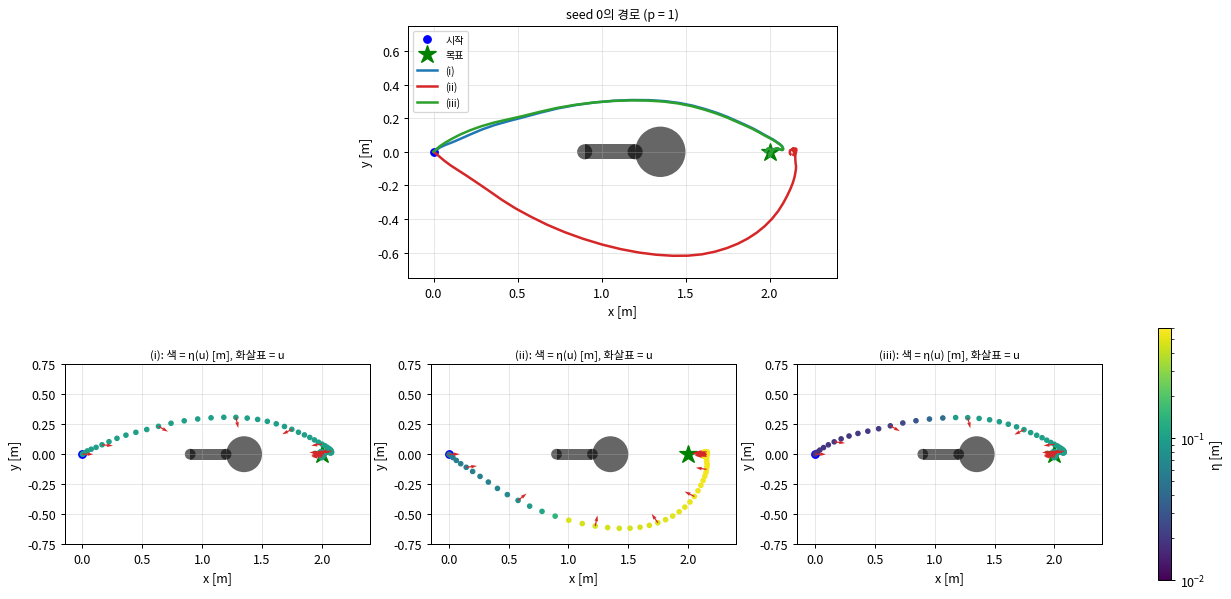

In [6]:
from matplotlib.colors import LogNorm
SEED_SHOW = 0
fig = plt.figure(figsize=(16, 8))
ax0 = fig.add_subplot(2, 1, 1)
draw_scene(ax0, lim=((-0.15, 2.4), (-0.75, 0.75)))
for (c, p), col in [(('i', 1), 'C0'), (('ii', 1), 'C3'), (('iii', 1), 'C2')]:
    ax0.plot(*RES[(c, p)][SEED_SHOW]['traj'].T, color=col, lw=2, label=label(c, p))
ax0.legend(fontsize=8, loc='upper left'); ax0.set_title(f'seed {SEED_SHOW}의 경로 (p = 1)', fontsize=10)

norm = LogNorm(0.01, 0.6)
for j, c in enumerate(['i', 'ii', 'iii']):
    ax = fig.add_subplot(2, 3, 4 + j)
    draw_scene(ax, lim=((-0.15, 2.4), (-0.75, 0.75)))
    tr = RES[(c, 1)][SEED_SHOW]['traj']
    if c == 'i':
        gap, idx, u = nearest(tr)
        eta = np.full(len(tr), S.ETA0)
    else:
        gap, eta, idx, u = directional_eta(tr, np.zeros(2), eta_of_mass(c, 1), REDUCED[c])
    sc = ax.scatter(*tr.T, c=eta, cmap='viridis', norm=norm, s=12, zorder=3)
    k = np.arange(0, len(tr), 6)
    ax.quiver(tr[k, 0], tr[k, 1], u[k, 0], u[k, 1], color='C3', scale=28, width=0.004, zorder=4)
    ax.set_title(f'{label(c, 1)}: 색 = η(u) [m], 화살표 = u', fontsize=9)
fig.colorbar(sc, ax=fig.axes[1:], fraction=0.02, label='η [m]')
plt.show()

**결과 해석** (표와 그림을 보며)
- **(i)은 반반에 가깝다.** 위 14 / 아래 18(44%). 대칭 장면이라 쪽은 seed가 정한다. 이것이 기준선이다.
- **(iii)은 (i)과 같다.** 위 14 / 아래 18이고, 32개 중 30개 seed가 (i)과 같은 쪽으로 갔다. 방향별 환산질량 η가 쪽 선택을 거의 바꾸지 못했다. p = 1/2도 같다.
- **(ii)는 위(가벼운 쪽)가 23 / 32(72%)로 많다.** 그런데 (i)과 같은 쪽으로 간 seed가 13개뿐이다. 경로 자체가 크게 바뀌었기 때문이다. 몸통 η가 0.45~0.56 m라 훨씬 멀리 돌아간다(위 그림 seed 0의 빨간 경로). 이 위쪽 쏠림이 팔의 ROM 잠금 때문인지는 5절의 대조 실험으로 확인한다.
- (ii) p = 1/2은 16 / 16이다.
- **아래 세 그림:** 출발 직후에는 가장 가까운 분절이 팔이고 u는 팔 길이 방향(+x)이다. 팔 길이 방향은 가장 가벼워서 (ii)·(iii)의 η가 가장 작다(어두운 점). 몸통 옆을 지날 때는 가장 가까운 분절이 몸통으로 바뀌어 η가 몸통 값((iii) 약 0.10 m, (ii) 0.45~0.56 m)으로 바뀐다.

## 4. 쪽별 이격 — 위로 지날 때와 아래로 지날 때

같은 경우 안에서 위로 지난 실행과 아래로 지난 실행을 나눠 비교한다. 팔과의 최소 이격, 몸통과의 최소 이격, 경로 길이, 도달 시간(목표 0.05 m 안).

In [7]:
def rng_str(vals, fmt='%.3f'):
    vals = [v for v in vals if v is not None]
    return '-' if not vals else (fmt + '~' + fmt) % (min(vals), max(vals))

print('%-14s %-4s %-3s | %-13s | %-13s | %-11s | %-11s | %s' % ('경우', '쪽', 'n', '팔 최소 이격', '몸통 최소 이격', '경로 길이', '도달 [s]', '도달 못 함'))
for c, p in CASES:
    for side in ('위', '아래'):
        rs = [r for r in RES[(c, p)] if r['side'] == side]
        if not rs:
            continue
        arr = [r['arrive'] for r in rs]
        print('%-14s %-4s %-3d | %-13s | %-13s | %-11s | %-11s | %d' % (label(c, p), side, len(rs), rng_str([r['arm'] for r in rs]),
              rng_str([r['torso'] for r in rs]), rng_str([r['length'] for r in rs], '%.2f'), rng_str(arr, '%.2f'), arr.count(None)))
    print()
print('팔의 η (p = 1): (ii) 자유 %.3f / 잠금 %.3f m, (iii) 자유 %.3f / 잠금 %.3f m'
      % (eta_of_mass('ii', 1)(3.0), eta_of_mass('ii', 1)(12.0), eta_of_mass('iii', 1)(reduced_mass(3.0)), eta_of_mass('iii', 1)(reduced_mass(12.0))))

경우             쪽    n   | 팔 최소 이격       | 몸통 최소 이격      | 경로 길이       | 도달 [s]      | 도달 못 함
(i)            위    14  | 0.130~0.190   | 0.093~0.105   | 2.37~2.55   | 1.55~2.40   | 0
(i)            아래   18  | 0.122~0.208   | 0.092~0.104   | 2.35~2.55   | 1.60~2.45   | 0

(ii)           위    23  | 0.382~0.427   | 0.412~0.429   | 2.87~3.04   | -           | 23
(ii)           아래   9   | 0.352~0.433   | 0.413~0.432   | 2.87~3.05   | -           | 9

(iii)          위    14  | 0.137~0.190   | 0.091~0.103   | 2.37~2.56   | 1.55~2.40   | 0
(iii)          아래   18  | 0.115~0.195   | 0.090~0.103   | 2.35~2.55   | 1.60~2.45   | 0

(ii) p=1/2     위    16  | 0.210~0.277   | 0.195~0.207   | 2.49~2.64   | 1.95~2.45   | 0
(ii) p=1/2     아래   16  | 0.198~0.277   | 0.194~0.206   | 2.46~2.65   | 2.00~2.40   | 0

(iii) p=1/2    위    14  | 0.127~0.190   | 0.092~0.105   | 2.37~2.56   | 1.55~2.40   | 0
(iii) p=1/2    아래   18  | 0.119~0.197   | 0.091~0.102   | 2.35~2.55   | 1.60~2.45   | 0

팔의 η (p = 1): (ii) 자유

**결과 해석**
- **(i)·(iii): 쪽에 따른 차이가 없다.** 팔과의 최소 이격, 몸통과의 최소 이격, 경로 길이, 도달 시간의 범위가 위아래에서 거의 겹친다. 무거운 쪽(아래)을 지날 때 팔과 더 멀지도 않았다((iii) 아래 0.115~0.195 m, 위 0.137~0.190 m).
- 가장 가까웠던 분절은 몸통이다(0.09~0.105 m, 몸통 η 근처). 팔과는 0.115 m 넘게 떨어져 지나갔고, 이것은 팔의 η((iii) 최대 0.079 m)보다 크다.
- **(ii): 쪽에 상관없이 팔·몸통 모두 0.35~0.43 m 떨어져 지나간다.** 몸통 η 때문이다. 경로가 2.87~3.05 m로 길고, **32개 모두 목표에 도달하지 못했다.** 2절에서 본 것처럼 목표가 몸통의 η 범위 안에 있어서 로봇은 목표 뒤쪽(위 그림의 x ≈ 2.15 m 근처)에서 멈춘다.
- (ii) p = 1/2은 몸통 η가 0.21~0.24 m라 몸통과 0.19~0.21 m 떨어져 지나가고, 목표에는 도달한다.
- 가설 "(iii)은 (ii)보다 쪽별 이격 차이가 작다"는 비교할 수 없었다. 두 경우 모두 쪽별 차이가 없었다.

## 5. 왜 그런가 — 팔의 비용이 경로에서 켜지는가

방향별 η는 그 분절의 비용이 켜질 때만(간격 < η) 경로를 바꿀 수 있다. 아래는 칸 하나의 사람 비용을 평면 위에 칠한 지도다(로봇 중심이 그 점에 있을 때). 세 경우의 seed 32개 경로를 함께 그린다.

실행 경로에서 팔과의 최소 이격 vs 팔의 η (p = 1)
  (ii) 팔 최소 이격 0.352~0.433 m, 팔 η 최댓값(잠금 수직) 0.169 m → 팔 비용이 켜진 실행 0 / 32
  (iii) 팔 최소 이격 0.115~0.195 m, 팔 η 최댓값(잠금 수직) 0.079 m → 팔 비용이 켜진 실행 0 / 32


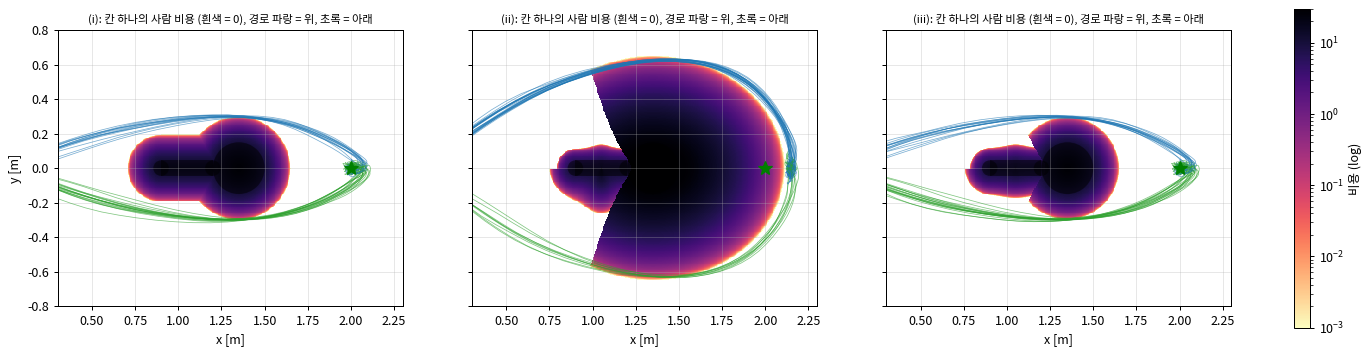

In [8]:
gx, gy = np.linspace(0.3, 2.3, 401), np.linspace(-0.8, 0.8, 321)
G = np.stack(np.meshgrid(gx, gy), -1)                       # [ny, nx, 2]
fig, axs = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for ax, c in zip(axs, ['i', 'ii', 'iii']):
    cost = case_cost(c, 1)(G, np.zeros(2))
    pc = ax.pcolormesh(gx, gy, np.where(cost > 0, cost, np.nan), cmap='magma_r', norm=LogNorm(1e-3, 30), shading='auto')
    draw_person(ax, alpha=0.5)
    for r in RES[(c, 1)]:
        ax.plot(*r['traj'].T, color='C0' if r['side'] == '위' else 'C2', lw=0.6, alpha=0.6)
    ax.plot(*S.GOAL, 'g*', ms=12)
    ax.set_aspect('equal'); ax.set_xlim(gx[0], gx[-1]); ax.set_ylim(gy[0], gy[-1]); ax.set_xlabel('x [m]')
    ax.set_title(f'{label(c, 1)}: 칸 하나의 사람 비용 (흰색 = 0), 경로 파랑 = 위, 초록 = 아래', fontsize=9)
axs[0].set_ylabel('y [m]')
fig.colorbar(pc, ax=axs, fraction=0.015, label='비용 (log)')
plt.show()

print('실행 경로에서 팔과의 최소 이격 vs 팔의 η (p = 1)')
for c in ['ii', 'iii']:
    f = eta_of_mass(c, 1)
    arm_eta_max = f(reduced_mass(12.0) if REDUCED[c] else 12.0)
    arms = [r['arm'] for r in RES[(c, 1)]]
    print('  (%s) 팔 최소 이격 %s m, 팔 η 최댓값(잠금 수직) %.3f m → 팔 비용이 켜진 실행 %d / %d'
          % (c, rng_str(arms), arm_eta_max, sum(a < arm_eta_max for a in arms), len(arms)))

**대조 실험 — ROM 잠금을 빼면 쪽 선택이 바뀌는가.** 팔의 위아래 비대칭은 ROM 잠금에서만 온다. 잠금을 뺀 팔 질량(위아래 모두 자유 값)으로 (ii)·(iii)을 같은 seed로 다시 돌린다. 잠금이 쪽을 정한다면 결과가 달라져야 한다. 이 대조는 원인 확인용이며 공통 모듈의 수치는 바꾸지 않는다(노트 안에서만 비용 함수를 따로 만든다).

In [9]:
M_ARM_FREE_INV = np.linalg.inv(S.M_ARM_FREE)

def cost_nolock(Pf, offsets, case, p=1):
    # (ii)/(iii)와 같고, 팔만 ROM 잠금 없이 자유 질량을 쓴다 (대조 실험용)
    gap, idx, u = nearest(Pf, offsets)
    m_arm = 1.0 / np.einsum('...i,ij,...j->...', u, M_ARM_FREE_INV, u)
    m = np.where(idx == 0, directional_mass(u, 'torso'), m_arm)
    if REDUCED[case]:
        m = reduced_mass(m)
    return eta_cost(gap, eta_of_mass(case, p)(m), S.W_HUMAN)

t0 = time.time()
for c in ['ii', 'iii']:
    sides = [run_case(partial(cost_nolock, case=c), s)['side'] for s in SEEDS]
    with_lock = [r['side'] for r in RES[(c, 1)]]
    print('(%s) 잠금 없음: 위 %d / 아래 %d | 잠금 있음: 위 %d / 아래 %d | 같은 seed에서 같은 쪽 %d / %d'
          % (c, sides.count('위'), sides.count('아래'), with_lock.count('위'), with_lock.count('아래'),
             sum(a == b for a, b in zip(sides, with_lock)), len(sides)))
print('(%.0f s)' % (time.time() - t0))

(ii) 잠금 없음: 위 22 / 아래 10 | 잠금 있음: 위 23 / 아래 9 | 같은 seed에서 같은 쪽 31 / 32
(iii) 잠금 없음: 위 14 / 아래 18 | 잠금 있음: 위 14 / 아래 18 | 같은 seed에서 같은 쪽 30 / 32
(133 s)


**결과 해석**
- **팔의 비용이 경로에서 켜지지 않는다.** 지도에서 (i)·(iii)의 경로는 몸통 비용 영역의 가장자리를 따라 돈다. 팔은 몸통보다 로봇 쪽으로 튀어나와 있지만, 몸통을 돌아가는 경로는 팔에서 이미 0.115 m 넘게 떨어져 있다. 팔의 η 영역(잠금 쪽도 최대 0.079 m) 안에 들어간 실행이 32개 중 0개다. 팔의 잠금/자유 차이가 경로를 바꿀 길이 없다. 팔이 몸통 비용 영역의 **그늘**에 있는 셈이다.
- (ii)의 지도에서는 몸통 영역이 팔을 거의 덮는다. 몸통 영역의 왼쪽 경계가 세로로 잘려 있는 곳은 가장 가까운 분절이 팔에서 몸통으로 바뀌는 곳이다. 여기서 η가 팔 값(0.01~0.17 m)에서 몸통 값(0.45 m 이상)으로 뛴다. 이 불연속은 18에서 다룬다.
- **잠금을 빼도 쪽 선택은 그대로다.** (ii)는 위 22 / 아래 10(잠금 있음 23 / 9), 같은 seed에서 31 / 32가 같은 쪽으로 갔다. (iii)도 30 / 32가 같다. 그러므로 (ii)의 위쪽 쏠림은 ROM 잠금(질량의 방향 차이)에서 온 것이 아니다. 잠금이 없으면 비용이 위아래 대칭이니, 이 쏠림은 이 seed 32개가 (ii)의 비용에서 만든 결과다. seed를 늘리면 반반에 가까워지는지는 이 노트에서 확인하지 않았다.

**정리:** 방향별 η는 "어느 쪽으로, 얼마나"를 정할 수 **있다**. 단, 그 분절의 비용이 실제로 켜지는 거리까지 경로가 들어갈 때만이다. 이 기준 자세에서는 팔이 몸통의 비용 그늘에 있어서, 팔의 ROM 비대칭이 쪽 선택도 쪽별 이격도 바꾸지 못했다.

## 6. 불연속 관찰 (기록만)

출발 직후 로봇은 팔 끝을 정면으로 본다. u가 팔 길이 방향(ROM 경계, u·n = 0) 근처에 있으면, 로봇이 경로 위아래로 조금만 움직여도 잠금 여부가 바뀌어 팔의 η가 뛴다(팔 길이 방향 1 kg ↔ 4 kg). 실행 경로에서 다음을 센다.
- **경계 근처 구간:** 가장 가까운 분절이 팔이고 u가 x축에서 15° 안쪽인 스텝
- 그 구간에서 잠금 여부가 바뀐 횟수(η가 뛴 횟수), 전체 실행에서 가장 가까운 분절이 바뀐 횟수
- 명령 변화량 ‖u_t − u_{t−1}‖의 평균: 경계 근처 구간 vs 그 밖(처음 3 s 안)

In [10]:
def jump_stats(r, c):
    tr, us = r['traj'][:-1], r['us']                         # 명령 u_t를 낸 위치 tr[t]
    gap, eta, idx, u = directional_eta(tr, np.zeros(2), eta_of_mass(c, 1), REDUCED[c])
    lock = (idx == 1) & (u @ S.ARM_NORMAL > 1e-9)
    near = (idx == 1) & (np.abs(u[:, 1]) < np.sin(np.radians(15)))
    flips = (lock[1:] != lock[:-1]) & (idx[1:] == 1) & (idx[:-1] == 1)
    du = np.linalg.norm(np.diff(us, axis=0), axis=1)          # du[t-1] = ‖u_t − u_{t−1}‖
    win = near[1:] & near[:-1]
    out = ~win & (np.arange(len(du)) < 60)
    return dict(win_t=win.sum() * S.DT, flips_win=int(flips[win].sum()), seg_sw=int((idx[1:] != idx[:-1]).sum()),
                du_win=du[win].mean() if win.any() else np.nan, du_out=du[out].mean())

for c in ['ii', 'iii']:
    st = [jump_stats(r, c) for r in RES[(c, 1)]]
    fw = [s['flips_win'] for s in st]
    print('(%s) 경계 근처 구간 길이 %s s | 그 구간에서 η가 뛴 횟수: %s (0회 %d, 1회 %d, 2회 이상 %d 실행) | 가장 가까운 분절 전환 %s회'
          % (c, rng_str([s['win_t'] for s in st], '%.2f'), rng_str(fw, '%d'), fw.count(0), fw.count(1), sum(f >= 2 for f in fw),
             rng_str([s['seg_sw'] for s in st], '%d')))
    for name, sel in [('η가 뛴 실행', [s for s in st if s['flips_win'] > 0]), ('뛰지 않은 실행', [s for s in st if s['flips_win'] == 0])]:
        if sel:
            print('     %-10s (%2d개): 명령 변화량 경계 근처 %.2f, 그 밖 %.2f m/s² (평균)'
                  % (name, len(sel), np.nanmean([s['du_win'] for s in sel]), np.mean([s['du_out'] for s in sel])))

(ii) 경계 근처 구간 길이 0.35~0.40 s | 그 구간에서 η가 뛴 횟수: 0~2 (0회 22, 1회 9, 2회 이상 1 실행) | 가장 가까운 분절 전환 1~1회
     η가 뛴 실행    (10개): 명령 변화량 경계 근처 1.36, 그 밖 1.62 m/s² (평균)
     뛰지 않은 실행   (22개): 명령 변화량 경계 근처 1.18, 그 밖 1.63 m/s² (평균)
(iii) 경계 근처 구간 길이 0.40~0.55 s | 그 구간에서 η가 뛴 횟수: 0~2 (0회 11, 1회 18, 2회 이상 3 실행) | 가장 가까운 분절 전환 1~1회
     η가 뛴 실행    (21개): 명령 변화량 경계 근처 1.66, 그 밖 1.33 m/s² (평균)
     뛰지 않은 실행   (11개): 명령 변화량 경계 근처 1.48, 그 밖 1.37 m/s² (평균)


**기록**
- 경계 근처 구간은 출발 직후 0.35~0.55 s다. 그 구간에서 잠금 여부가 바뀐(η가 뛴) 횟수는 0~2회다. 1회 이상 뛴 실행은 (ii) 32개 중 10개, (iii) 32개 중 21개다. 가장 가까운 분절 전환(팔 → 몸통)은 모든 실행에서 1회다.
- 명령 변화량은 경계 근처 구간이 그 밖보다 뚜렷하게 크지 않다. (iii)에서 η가 뛴 실행은 1.66 vs 1.33 m/s², 뛰지 않은 실행은 1.48 vs 1.37 m/s²다. (ii)는 경계 근처가 오히려 작다(1.36 vs 1.62, 1.18 vs 1.63).
- 이 구간에서 로봇은 출발점 근처에 있다(정지에서 ±4 m/s²로 0.55 s 동안 0.6 m 넘게 갈 수 없다). 그래서 팔과의 간격이 팔의 η보다 커서, 실행 위치에서 η가 뛰어도 그 자리의 비용은 0이다. 뛰는 η가 영향을 준다면 사람 근처까지 뻗은 rollout 후보들을 통해서다.

## 7. 팔이 몸통 그늘 밖에 있을 때 — "팔 뻗은 자세"

### 질문
5절에서 방향 효과가 안 나온 원인은 팔이 몸통 그늘에 있어서였다. 그렇다면 팔이 로봇 경로에 직접 들어와 가장 가까운 분절이 될 때는 방향별 η가 이격과 비켜 가는 쪽을 바꿀까?

### 장면 변형 정하기
기본 장면은 그대로 두고, 이 절에서만 쓰는 자세를 새 이름(`common14/pose.py`의 `make_pose`)으로 만든다. 바꾸는 것은 **몸통 위치와 팔 방향(과 잠금 방향)**뿐이다. 모양(몸통 반지름 0.15 m, 팔 길이 0.3 m·반지름 0.045 m), 관성값(몸통 diag(40, 32), 팔 길이 1 kg / 수직 3 kg, 잠금 4배), 로봇, 시작·목표, MPPI, η 규칙(2절의 η_L, 15의 몸통 기준)은 그대로다. 팔의 관성은 팔과 함께 돌린다(팔 기준 길이·수직 값이 같다).

| 정한 값 | 값 | 이유 |
|---|---|---|
| 몸통 중심 | (1.00, 0.35) m | 조건 1: 경로(y = 0) 위 로봇과 몸통의 간격이 0.35 − 0.15 − 0.05 = 0.15 m로, 몸통 η 0.10 m(15의 몸통 기준)보다 크다. x = 1.0은 시작(0)과 목표(2)의 가운데라, 잠금 방향을 뒤집으면 기하가 좌우 거울상이 된다 |
| 팔 방향 | 몸통에서 아래(−y)로 | 조건 2: 팔 끝이 (1.00, −0.10)까지 내려와 경로를 막는다(표면 −0.145 m). 로봇은 팔 끝을 돌아가야 목표에 간다 |
| 잠금 방향 | 팔 수직 ±x 두 가지 | "다가오는 쪽": 로봇이 왼쪽에서 팔을 +x로 밀 때 잠김. "지나간 쪽": 오른쪽에서 −x로 밀 때 잠김 |

팔 길이가 0.3 m로 고정이라, 팔 끝은 몸통 중심에서 최대 0.45 m까지만 닿는다. (ii)의 몸통 η(0.45 m 이상)까지 경로에 닿지 않게 하는 위치는 없다. 그래서 조건 1은 15의 몸통 기준 η(0.10 m)로 맞췄다. (ii)에서 몸통 비용이 실제로 켜졌는지는 아래에서 센다.

잠금 다가오는 쪽: 어깨 [1.  0.2], 손 [ 1.  -0.1], 잠금 방향(이쪽으로 밀면 잠김) [ 1. -0.]
잠금 지나간 쪽 : 어깨 [1.  0.2], 손 [ 1.  -0.1], 잠금 방향(이쪽으로 밀면 잠김) [-1.  0.]
경로(y = 0) 위 로봇과 몸통의 간격 0.150 m (몸통 η: (i) 0.100, (iii) 0.097, (ii) 0.450 m, 경로 쪽 u = +y 기준)


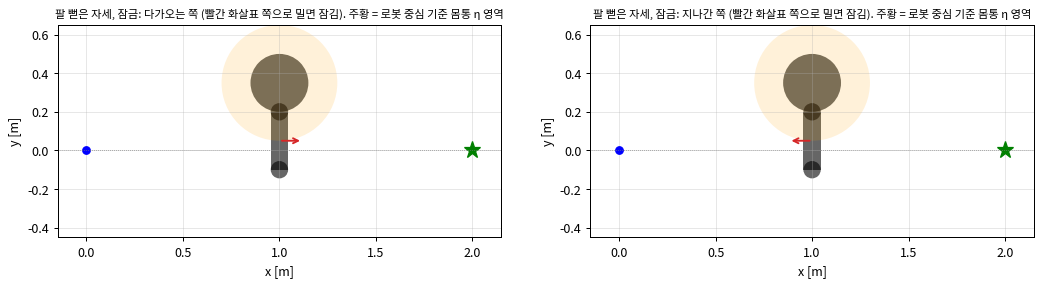

In [11]:
from common14.pose import make_pose, pose_gaps, pose_mass, pose_directional_eta, pose_cost_uniform, pose_cost_directional, draw_pose

REACH_C, REACH_DIR = (1.00, 0.35), (0.0, -1.0)
LOCKS = {'다가오는 쪽': -1, '지나간 쪽': +1}          # make_pose의 lock_sign
POSES = {k: make_pose(REACH_C, REACH_DIR, s, name=k) for k, s in LOCKS.items()}
for k, pz in POSES.items():
    print('잠금 %-6s: 어깨 %s, 손 %s, 잠금 방향(이쪽으로 밀면 잠김) %s' % (k, pz['arm_a'].round(3), pz['arm_b'].round(3), pz['lock_dir'].round(0)))
print('경로(y = 0) 위 로봇과 몸통의 간격 %.3f m (몸통 η: (i) %.3f, (iii) %.3f, (ii) %.3f m, 경로 쪽 u = +y 기준)'
      % (REACH_C[1] - S.TORSO_R - S.ROBOT_R, S.ETA0, eta_of_mass('iii', 1)(reduced_mass(directional_mass(ey, 'torso'))),
         eta_of_mass('ii', 1)(directional_mass(ey, 'torso'))))

fig, axs = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, (k, pz) in zip(axs, POSES.items()):
    draw_pose(ax, pz)
    ax.add_patch(plt.Circle(pz['torso_c'], S.TORSO_R + S.ROBOT_R + S.ETA0, color='orange', alpha=0.15, lw=0))
    ax.plot(*S.START, 'bo'); ax.plot(*S.GOAL, 'g*', ms=14); ax.axhline(0, color='gray', lw=0.6, ls=':')
    ax.set_aspect('equal'); ax.set_xlim(-0.15, 2.15); ax.set_ylim(-0.45, 0.65); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
    ax.set_title(f'팔 뻗은 자세, 잠금: {k} (빨간 화살표 쪽으로 밀면 잠김). 주황 = 로봇 중심 기준 몸통 η 영역', fontsize=9)
plt.show()

### 7a. 잠금 방향 뒤집기

같은 자세에서 잠금 방향만 반대로 한 두 경우를 (i)·(ii)·(iii)으로 비교한다(p = 1, seed 16개). 측정은 다음과 같다.
- 팔과의 최소 이격, 그 순간 로봇이 팔을 미는 방향의 팔 유효질량 m_h(잠금이면 4배)
- 경로 길이, 도달 시간
- **팔 비용이 켜진 스텝:** 실행 경로에서 가장 가까운 분절이 팔이고 간격이 팔 η보다 작은 스텝 수
- **계획에서 팔 비용이 켜진 비율:** 매 스텝 MPPI의 평균 계획(30칸) 중 한 칸이라도 위 조건을 만족한 스텝의 비율. MPPI가 비용을 보는 곳은 실행 경로가 아니라 미래 계획이므로 함께 센다
- 몸통 비용이 켜진 스텝(조건 1 확인)
- 가장 가까운 분절이 팔인 스텝 비율

**예측해 보기:** 로봇은 왼쪽에서 다가와 팔 끝 아래를 지나간다. 팔과 가장 가까운 순간 로봇은 팔의 어느 쪽에 있을까? "다가오는 쪽 잠금"과 "지나간 쪽 잠금" 중 어느 쪽에서 이격이 더 클까?

In [12]:
SEEDS7 = range(16)

def pose_eta_fn(case):
    return (lambda m: np.full(np.shape(m), S.ETA0)) if case == 'i' else eta_of_mass(case, 1)

def pose_case_cost(case, pose):
    if case == 'i':
        return partial(pose_cost_uniform, pose=pose)
    return partial(pose_cost_directional, pose=pose, eta_of_mass=eta_of_mass(case, 1), reduced=REDUCED[case])

def run_pose(case, lock, seed):
    pz, f, red = POSES[lock], pose_eta_fn(case), REDUCED.get(case, False)
    r = run_mpc(static_person, human_cost=pose_case_cost(case, pz), seed=seed, snapshot_steps=range(S.STEPS))
    tr, us = r['traj'], r['us']
    arr = arrival_time(tr)
    n = S.STEPS if arr is None else int(round(arr / S.DT))             # 도달 전 스텝만 센다
    gap, eta, idx, u = pose_directional_eta(tr, pz, f, red)
    on_arm, on_torso = (idx == 1) & (gap < eta), (idx == 0) & (gap < eta)
    plan_arm, plan_torso = [], []
    for s in range(n):
        g2, e2, i2, _ = pose_directional_eta(r['snaps'][s]['plan'][1:], pz, f, red)
        plan_arm.append(((i2 == 1) & (g2 < e2)).any()); plan_torso.append(((i2 == 0) & (g2 < e2)).any())
    gaps = pose_gaps(tr, pz)
    k = int(np.argmin(gaps[:, 1]))
    u_arm = (pz['com'][1] - tr[k]) / np.linalg.norm(pz['com'][1] - tr[k])
    # 불연속: 잠금 여부가 바뀐 스텝(팔이 가장 가까운 동안), 가장 가까운 분절이 바뀐 스텝
    lock_flag = (idx == 1) & (u @ pz['lock_dir'] > 1e-9)
    rom = [t for t in range(1, n) if lock_flag[t] != lock_flag[t - 1] and idx[t] == 1 and idx[t - 1] == 1]
    sw = [t for t in range(1, n) if idx[t] != idx[t - 1]]
    du = np.linalg.norm(np.diff(us, axis=0), axis=1)                   # du[t-1] = ‖u_t − u_{t−1}‖
    other = [t for t in range(1, n) if t not in rom and t not in sw]
    return dict(traj=tr, idx=idx, eta=eta, arm=gaps[:, 1].min(), m_close=float(pose_mass(u_arm, 'arm', pz)),
                length=path_length(tr), arrive=arr, on_arm=int(on_arm[:n].sum()), on_torso=int(on_torso[:n].sum()),
                plan_arm=float(np.mean(plan_arm)), plan_torso=float(np.mean(plan_torso)), arm_near=float((idx[:n] == 1).mean()),
                ymax=tr[:, 1].max(), rom=len(rom), sw=len(sw), du_rom=[du[t - 1] for t in rom], du_sw=[du[t - 1] for t in sw],
                du_other=float(np.mean([du[t - 1] for t in other])))

t0 = time.time()
RES7 = {(c, lk): [run_pose(c, lk, s) for s in SEEDS7] for c in ('i', 'ii', 'iii') for lk in LOCKS}
print('실행 시간 %.0f s' % (time.time() - t0))
print('(i)의 두 잠금 경우 궤적 최대 차이: %.1e m (균일 η는 잠금을 쓰지 않는다)'
      % max(np.abs(a['traj'] - b['traj']).max() for a, b in zip(RES7[('i', '다가오는 쪽')], RES7[('i', '지나간 쪽')])))

실행 시간 205 s
(i)의 두 잠금 경우 궤적 최대 차이: 0.0e+00 m (균일 η는 잠금을 쓰지 않는다)


In [13]:
print('%-6s %-7s | %-20s | %-12s | %-10s | %-15s | %-12s | %-11s | %-11s | %-9s' % ('경우', '잠금', '팔 최소 이격 (평균)', '그때 팔 m_h', '경로 길이', '도달 [s]',
      '팔 비용 스텝', '계획 팔 비용', '몸통 비용 스텝', '팔이 가장 가까움'))
for c in ('i', 'ii', 'iii'):
    for lk in LOCKS:
        rs = RES7[(c, lk)]
        arms = [r['arm'] for r in rs]
        print('%-6s %-7s | %-12s (%.3f) | %-12s | %-10s | %-15s | %-12s | %-11s | %-11s | %s' % (
            '(%s)' % c, lk, rng_str(arms), np.mean(arms), ' '.join('%.1f' % m for m in sorted({round(r['m_close'], 1) for r in rs})),
            rng_str([r['length'] for r in rs], '%.2f'), rng_str([r['arrive'] for r in rs], '%.2f') + (' 못 함 %d' % sum(r['arrive'] is None for r in rs) if any(r['arrive'] is None for r in rs) else ''),
            rng_str([r['on_arm'] for r in rs], '%d'), rng_str([r['plan_arm'] for r in rs], '%.2f'),
            rng_str([r['on_torso'] for r in rs], '%d') + ' / 계획 %s' % rng_str([r['plan_torso'] for r in rs], '%.2f'),
            rng_str([r['arm_near'] for r in rs], '%.2f')))
    print()
for c in ('ii', 'iii'):
    d = np.mean([r['arm'] for r in RES7[(c, '다가오는 쪽')]]) - np.mean([r['arm'] for r in RES7[(c, '지나간 쪽')]])
    print('(%s) 팔 최소 이격 평균 차이 (다가오는 쪽 잠금 − 지나간 쪽 잠금): %+.4f m' % (c, d))
print('팔 η (p = 1): 길이 방향 자유 1 kg → (ii) %.3f, (iii) %.3f m | 길이 방향 잠금 4 kg → (ii) %.3f, (iii) %.3f m'
      % (eta_of_mass('ii', 1)(1.0), eta_of_mass('iii', 1)(reduced_mass(1.0)), eta_of_mass('ii', 1)(4.0), eta_of_mass('iii', 1)(reduced_mass(4.0))))

경우     잠금      | 팔 최소 이격 (평균)         | 그때 팔 m_h     | 경로 길이      | 도달 [s]          | 팔 비용 스텝      | 계획 팔 비용     | 몸통 비용 스텝    | 팔이 가장 가까움
(i)    다가오는 쪽  | 0.085~0.100  (0.095) | 1.0 4.0 4.1  | 2.34~2.53  | 1.45~2.40       | 0~2          | 0.09~0.32   | 0~0 / 계획 0.00~0.00 | 0.44~0.72
(i)    지나간 쪽   | 0.085~0.100  (0.095) | 1.0 4.0      | 2.34~2.53  | 1.45~2.40       | 0~2          | 0.09~0.32   | 0~0 / 계획 0.00~0.00 | 0.44~0.72

(ii)   다가오는 쪽  | 0.047~0.061  (0.055) | 1.0 4.0 4.1  | 2.31~2.50  | 1.45~2.35       | 0~1          | 0.00~0.17   | 0~0 / 계획 0.00~0.00 | 0.45~0.72
(ii)   지나간 쪽   | 0.030~0.057  (0.045) | 1.0          | 2.32~2.50  | 1.45~2.40       | 0~1          | 0.00~0.20   | 0~0 / 계획 0.00~0.00 | 0.44~0.70

(iii)  다가오는 쪽  | 0.041~0.058  (0.051) | 1.0 4.0 4.1  | 2.31~2.49  | 1.45~2.30       | 0~1          | 0.00~0.19   | 0~0 / 계획 0.00~0.00 | 0.46~0.72
(iii)  지나간 쪽   | 0.027~0.052  (0.041) | 1.0          | 2.31~2.50  | 1.45~2.40       | 0~1          | 0.00~0.20   | 0~0 / 계획 0.00~

**결과 해석** (표를 보며)
- **(i)은 잠금 방향과 무관하다.** 두 경우의 궤적이 완전히 같다(최대 차이 0). 균일 η는 질량을 쓰지 않기 때문이다.
- **조건 1은 (ii)에서도 지켜졌다.** 몸통 비용이 켜진 스텝이 모든 경우에 실행 0, 계획 0이다. (ii)의 몸통 η는 0.45 m지만, 경로 근처에서는 팔이 더 가까워 가장 가까운 분절 비용이 팔의 η를 쓴다.
- **잠금 쪽을 밀 때 이격이 더 크다는 방향은 나왔지만 차이는 작다.** 팔과 가장 가까운 순간 로봇은 아직 팔의 왼쪽(다가오는 쪽)에서 팔 끝 아래로 들어가고 있다. 그래서 "다가오는 쪽 잠금"이면 그 순간 질량이 대부분 4 kg(잠금), "지나간 쪽 잠금"이면 1 kg이다(표의 "그때 팔 m_h"). 이때 평균 이격은 (ii) 0.055 vs 0.045 m, (iii) 0.051 vs 0.041 m로 잠금 쪽을 밀 때 약 1 cm 크다. 다만 seed 범위는 겹친다.
- **(iii)의 차이가 (ii)보다 작다는 가설은 나오지 않았다.** 평균 차이가 (ii) +1.00 cm, (iii) +0.95 cm로 거의 같다. 가장 가까운 순간에 쓰이는 것은 팔 **길이 방향** 질량(1 kg ↔ 4 kg)이다. 이 방향의 η 차이는 (ii) 0.014 → 0.056 m, (iii) 0.019 → 0.050 m로, 팔 수직 방향(4배 vs 1.88배)만큼 대비가 벌어지지 않는다. 실측 이격 차이(약 1 cm)는 두 η 차이(4.2 cm, 3.1 cm)보다 훨씬 작다. 왜 그런지(15에서 본 샘플 잡음의 여유 등)는 이 노트에서 나누어 확인하지 않았다.
- 경로 길이와 도달 시간은 잠금 방향에 따라 거의 바뀌지 않았다.
- **팔 비용이 켜진 스텝이 매우 적다.** 실행 경로에서는 0~1스텝이다. 계획에서도 (ii)·(iii)은 스텝의 0~20%에서만 팔 비용이 켜졌다(균일 η (i)은 9~32%). 가장 가까운 분절이 팔인 스텝은 44~72%로 많은데도 그렇다.

### 7a-2. 팔 비용이 켜진 스텝이 적은 이유 — 다른 자세도 확인

팔 비용이 켜진 비율이 매우 작아서 장면을 다시 정하려고 팔 방향과 몸통 위치를 바꾼 자세 4개를 더 돌렸다. 조건 1(경로-몸통 간격 > 0.10 m)과 조건 2(팔 끝이 경로 쪽으로 나옴)는 모두 지킨다.

In [14]:
CANDIDATES = {'아래로 (이 절의 자세)': ((1.00, 0.35), (0, -1)), '아래로, 더 깊이': ((1.00, 0.32), (0, -1)),
              '오른쪽 아래로': ((0.90, 0.35), (0.6, -0.8)), '오른쪽 아래로, 더 깊이': ((0.95, 0.32), (0.5, -0.866)),
              '왼쪽 아래로': ((1.10, 0.35), (-0.6, -0.8))}
t0 = time.time()
print('(iii), seed 4개, 잠금 두 방향 합쳐 8개 실행씩')
print('%-16s | %-14s | %-11s | %-12s | %-14s | %s' % ('자세', '팔 끝 y [m]', '경로-몸통 간격', '팔 비용 스텝', '계획 팔 비용', '팔 최소 이격 때 m_h [kg]'))
for name, (c0, d0) in CANDIDATES.items():
    rows7 = []
    for sgn in (-1, +1):
        pz = make_pose(c0, d0, sgn)
        for s in range(4):
            r = run_mpc(static_person, human_cost=partial(pose_cost_directional, pose=pz, eta_of_mass=eta_of_mass('iii', 1), reduced=True),
                        seed=s, snapshot_steps=range(S.STEPS))
            tr = r['traj']; arr = arrival_time(tr); n = S.STEPS if arr is None else int(round(arr / S.DT))
            gap, eta, idx, u = pose_directional_eta(tr, pz, eta_of_mass('iii', 1), True)
            pa = np.mean([((lambda g: (g[2] == 1) & (g[0] < g[1]))(pose_directional_eta(r['snaps'][t]['plan'][1:], pz, eta_of_mass('iii', 1), True))).any() for t in range(n)])
            k = int(np.argmin(pose_gaps(tr, pz)[:, 1]))
            ua = (pz['com'][1] - tr[k]) / np.linalg.norm(pz['com'][1] - tr[k])
            rows7.append((int(((idx == 1) & (gap < eta))[:n].sum()), pa, float(pose_mass(ua, 'arm', pz))))
    pz = make_pose(c0, d0)
    print('%-16s | %-14.3f | %-11.3f | %-12s | %-14s | %s' % (name, pz['arm_b'][1], c0[1] - S.TORSO_R - S.ROBOT_R, rng_str([r[0] for r in rows7], '%d'),
          rng_str([r[1] for r in rows7], '%.2f'), ' '.join('%.1f' % m for m in sorted({round(r[2], 1) for r in rows7}))))
print('(%.0f s)' % (time.time() - t0))

(iii), seed 4개, 잠금 두 방향 합쳐 8개 실행씩
자세               | 팔 끝 y [m]      | 경로-몸통 간격    | 팔 비용 스텝      | 계획 팔 비용        | 팔 최소 이격 때 m_h [kg]
아래로 (이 절의 자세)    | -0.100         | 0.150       | 0~1          | 0.00~0.19      | 1.0 4.0
아래로, 더 깊이        | -0.130         | 0.120       | 0~1          | 0.00~0.14      | 1.0 4.0 4.1
오른쪽 아래로          | -0.010         | 0.150       | 0~0          | 0.00~0.00      | 1.0 1.1 4.2 4.3
오른쪽 아래로, 더 깊이    | -0.070         | 0.120       | 0~1          | 0.00~0.14      | 1.0 4.1 4.2
왼쪽 아래로           | -0.010         | 0.150       | 0~1          | 0.00~0.10      | 1.1 4.3 4.4 4.5 4.6
(106 s)


**결과 해석:** 다섯 자세 모두 실행 경로에서 팔 비용이 켜진 스텝이 0~1이고, 계획에서도 0~19%였다. 다시 정해도 비율이 커지지 않았다. 원인은 두 가지로 보인다.
- **팔 끝을 돌아간다.** 팔 길이가 0.3 m로 고정이고 몸통은 경로에서 0.30 m 넘게 떨어져야 하므로, 팔 끝은 경로를 최대 십여 cm만 넘는다. 로봇은 어느 자세에서든 팔 끝을 돌아가고, 지나가는 시간이 짧다.
- **팔 끝에서 u는 팔 길이 방향이다.** u는 "로봇 → 팔 무게중심" 방향이라, 팔 끝 근처에서는 거의 팔 축을 따른다. 그래서 가장 가까운 순간의 질량이 모든 자세에서 1 kg(자유) 또는 4 kg(잠금) 근처이고, η가 0.014~0.056 m로 작다. 팔 수직 질량(3 kg / 12 kg)이 쓰이는 것은 로봇이 팔 옆(무게중심 옆)을 지날 때인데, 이 조건 안에서는 그런 경로가 나오지 않는다.

그래서 이 절은 "아래로" 자세(몸통 (1.00, 0.35))로 진행했다. 팔 비용이 켜진 비율이 작다는 점은 그대로 결과로 남긴다.

### 그림 — 대표 경로

seed 0의 경로를 잠금 방향별로 겹쳐 그린다(실선 = 다가오는 쪽 잠금, 점선 = 지나간 쪽 잠금). 점의 색은 그 위치의 η(u), 모양은 가장 가까운 분절(동그라미 = 팔, 네모 = 몸통)이다. 빨간 화살표는 "다가오는 쪽" 잠금 방향(+x), 파란 화살표는 "지나간 쪽" 잠금 방향(−x)이다.

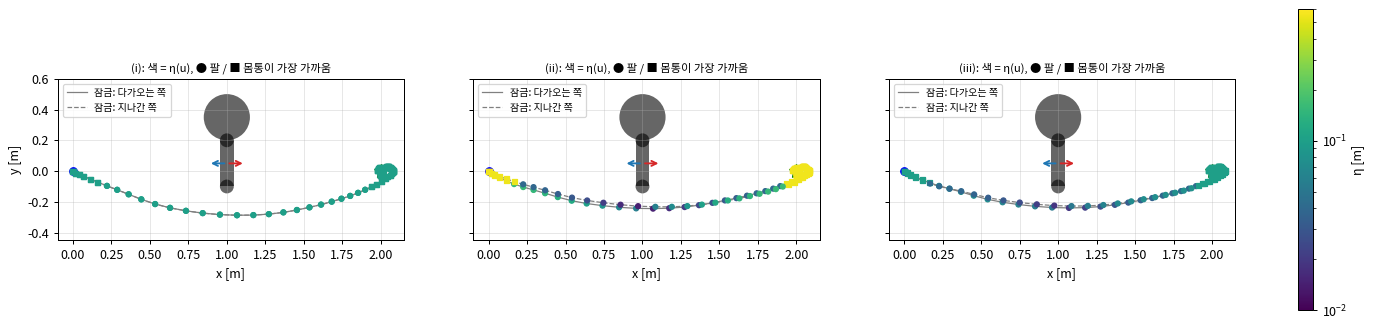

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
norm = LogNorm(0.01, 0.6)
for ax, c in zip(axs, ['i', 'ii', 'iii']):
    pz = POSES['다가오는 쪽']
    draw_pose(ax, pz, show_lock=False)
    m = pz['com'][1]
    ax.annotate('', xy=m + 0.12 * POSES['다가오는 쪽']['lock_dir'], xytext=m, arrowprops=dict(arrowstyle='->', color='C3', lw=1.5))
    ax.annotate('', xy=m + 0.12 * POSES['지나간 쪽']['lock_dir'], xytext=m, arrowprops=dict(arrowstyle='->', color='C0', lw=1.5))
    for lk, ls in [('다가오는 쪽', '-'), ('지나간 쪽', '--')]:
        r = RES7[(c, lk)][0]
        tr = r['traj']
        ax.plot(*tr.T, ls, color='gray', lw=1, label=f'잠금: {lk}')
        for seg, mk in [(1, 'o'), (0, 's')]:
            sel = r['idx'] == seg
            sc = ax.scatter(tr[sel, 0], tr[sel, 1], c=r['eta'][sel], cmap='viridis', norm=norm, s=16, marker=mk, zorder=3)
    ax.plot(*S.START, 'bo'); ax.plot(*S.GOAL, 'g*', ms=12)
    ax.set_aspect('equal'); ax.set_xlim(-0.1, 2.15); ax.set_ylim(-0.45, 0.6); ax.set_xlabel('x [m]')
    ax.set_title(f'{label(c, 1)}: 색 = η(u), ● 팔 / ■ 몸통이 가장 가까움', fontsize=9); ax.legend(fontsize=8, loc='upper left')
axs[0].set_ylabel('y [m]')
fig.colorbar(sc, ax=axs, fraction=0.012, label='η [m]')
plt.show()

### 7b. 비켜 가는 쪽

이 자세에서 팔은 몸통에 붙어 아래로 뻗어 있다. 팔의 "다른 쪽"(팔과 몸통 사이)으로는 지나갈 수 없다. 팔 끝 아래가 아닌 길은 몸통 위로 크게 돌아가는 길뿐이고, 그것은 팔이 아니라 몸통을 비켜 가는 선택이다. 실제로 모든 실행이 어느 쪽으로 갔는지 확인한다.

In [16]:
for c in ('i', 'ii', 'iii'):
    for lk in LOCKS:
        rs = RES7[(c, lk)]
        y_cross = [r['traj'][np.argmax(r['traj'][:, 0] >= REACH_C[0]), 1] for r in rs]      # x = 1.0을 처음 지날 때 y
        below = sum(y < POSES[lk]['arm_b'][1] for y in y_cross)
        print('(%-3s) 잠금 %-6s: 팔 끝 아래로 %2d / %d, x = 1.0에서 y %s m, 실행 중 y 최댓값 %s m'
              % (c, lk, below, len(rs), rng_str(y_cross), rng_str([r['ymax'] for r in rs])))

(i  ) 잠금 다가오는 쪽: 팔 끝 아래로 16 / 16, x = 1.0에서 y -0.295~-0.280 m, 실행 중 y 최댓값 0.011~0.050 m
(i  ) 잠금 지나간 쪽 : 팔 끝 아래로 16 / 16, x = 1.0에서 y -0.295~-0.280 m, 실행 중 y 최댓값 0.011~0.050 m
(ii ) 잠금 다가오는 쪽: 팔 끝 아래로 16 / 16, x = 1.0에서 y -0.254~-0.236 m, 실행 중 y 최댓값 0.011~0.050 m
(ii ) 잠금 지나간 쪽 : 팔 끝 아래로 16 / 16, x = 1.0에서 y -0.245~-0.227 m, 실행 중 y 최댓값 0.011~0.050 m
(iii) 잠금 다가오는 쪽: 팔 끝 아래로 16 / 16, x = 1.0에서 y -0.250~-0.230 m, 실행 중 y 최댓값 0.011~0.050 m
(iii) 잠금 지나간 쪽 : 팔 끝 아래로 16 / 16, x = 1.0에서 y -0.241~-0.224 m, 실행 중 y 최댓값 0.011~0.050 m


**결과:** 모든 실행(3경우 × 잠금 2 × seed 16)이 팔 끝 아래로 지나갔고, 실행 중 y는 0.05 m를 넘지 않았다(몸통 위로 돌아간 실행 없음). 기하상 팔에 대해서는 한쪽(팔 끝 쪽)만 가능하므로 16의 3절 같은 쪽 선택 비교는 하지 않았다.

### 불연속 기록 (고치지 않음)

실행 경로(도달 전)에서 ROM 경계(팔이 가장 가까운 동안 잠금 여부가 바뀜)와 가장 가까운 분절 전환을 몇 번 넘었는지, 그 스텝의 명령 변화량 ‖u_t − u_{t−1}‖을 다른 스텝과 비교한다.

In [17]:
print('%-6s %-7s | %-10s | %-14s | %-10s | %-14s | %s' % ('경우', '잠금', 'ROM 경계', '그때 명령 변화', '분절 전환', '그때 명령 변화', '그 밖 스텝 명령 변화 (평균)'))
for c in ('ii', 'iii'):
    for lk in LOCKS:
        rs = RES7[(c, lk)]
        dr = [x for r in rs for x in r['du_rom']]; ds = [x for r in rs for x in r['du_sw']]
        print('%-6s %-7s | %-10s | %-14s | %-10s | %-14s | %.2f m/s²' % ('(%s)' % c, lk, rng_str([r['rom'] for r in rs], '%d') + '회',
              '%.2f m/s²' % np.mean(dr) if dr else '-', rng_str([r['sw'] for r in rs], '%d') + '회', '%.2f m/s²' % np.mean(ds) if ds else '-',
              np.mean([r['du_other'] for r in rs])))

경우     잠금      | ROM 경계     | 그때 명령 변화       | 분절 전환      | 그때 명령 변화       | 그 밖 스텝 명령 변화 (평균)
(ii)   다가오는 쪽  | 1~1회       | 0.88 m/s²      | 2~2회       | 1.16 m/s²      | 1.25 m/s²
(ii)   지나간 쪽   | 1~1회       | 0.83 m/s²      | 2~2회       | 1.20 m/s²      | 1.29 m/s²
(iii)  다가오는 쪽  | 1~1회       | 0.88 m/s²      | 2~2회       | 1.16 m/s²      | 1.29 m/s²
(iii)  지나간 쪽   | 1~1회       | 0.84 m/s²      | 2~2회       | 1.16 m/s²      | 1.30 m/s²


**기록:** 모든 실행에서 ROM 경계를 1회(팔 끝 아래를 지나며 팔의 왼쪽 → 오른쪽으로 넘어갈 때), 가장 가까운 분절 전환을 2회(몸통 → 팔 → 몸통) 넘었다. 그 스텝의 명령 변화량(ROM 경계 0.83~0.88, 분절 전환 1.16~1.20 m/s²)은 그 밖 스텝(1.25~1.30 m/s²)보다 크지 않았다. 넘는 순간 로봇이 그 분절의 η 밖에 있으면(팔 비용 스텝 0~1) 그 자리의 비용은 0이라 η가 뛰어도 실행 위치에서는 차이가 없다.

**7절에서 본 것:** 팔이 경로를 가로막으면 로봇은 팔 끝을 돌아가므로, 가장 가까운 순간 u의 방향이 팔 축에 가깝다. 그래서 ROM 잠금의 주 대상인 팔 수직 질량이 쓰이지 않았다. 8절에서는 로봇이 팔 옆을 지나가는 자세로 이를 다시 본다.

## 8. 팔 옆을 지나갈 때와 u 정의 비교 — "팔 옆 자세"

### 질문
- 로봇이 팔의 옆면을 따라 지나가면 팔 수직 질량과 ROM 잠금이 이격에 나타나는가?
- u를 "분절 무게중심 방향"으로 정의할 때와 "가장 가까운 점 방향"으로 정의할 때 무엇이 달라지는가?

### 연결
연구의 충돌 방향 정의는 지금 "로봇 점 → 가장 가까운 분절 무게중심"(Indy7 정의)으로 정해져 있다. 이 절은 그 정의를 유지할지 판단할 근거를 모은다. 비교만 하며, common14의 기본 정의(`geometry.nearest`, `pose.pose_nearest`)는 바꾸지 않는다. 가장 가까운 점 정의는 `common14/pose.py`에 함수를 추가해서 쓴다(`pose_nearest_point`, `pose_directional_eta_point`, `pose_cost_directional_point`).

### 장면 정하기
7절처럼 `make_pose`로 새 자세를 만든다. 바꾸는 것은 **몸통 위치와 팔 방향(과 잠금 방향)**뿐이다. 팔 길이, 관성값, 로봇, 시작·목표, MPPI, η 규칙(2절의 η_L, 15의 몸통 기준)은 그대로다.

| 정한 값 | 값 | 이유 |
|---|---|---|
| 몸통 중심 | (1.274, 0.31) m | 몸통 비용 영역이 경로에 닿지 않게 한다. 경로(y = 0) 위 로봇과 몸통의 간격이 0.110 m로, 몸통 η 0.100 m((i))·0.097 m((iii))보다 크다. x는 팔 무게중심이 x = 1.0(시작과 목표의 가운데)에 오도록 정했다 |
| 팔 방향 | 몸통에서 왼쪽 아래, 경로와 24° | 팔은 몸통 표면에서 시작한다. 그래서 경로와 나란하게(0°) 두면 팔 옆면과 경로의 간격이 0.215 m로 팔 η 밖이다. 팔 끝 쪽 간격이 팔 수직 자유 η(0.042 m)보다 작아지는 최소 각도가 22.6°라서, 그보다 조금 큰 24°로 정했다(직진 경로의 팔 최소 간격 0.032 m). 손 끝 (0.863, 0.127)은 경로 위쪽에 있어 경로를 막지 않는다. 로봇은 팔 끝을 돌아가지 않고 팔 아래를 따라 지나간다 |
| 잠금 방향 | 팔 수직 두 가지 | 로봇은 팔 아래(경로 쪽)에서 팔을 위(몸통 쪽)로 민다. "잠금 있음"은 잠금 방향이 이쪽인 경우(빨간 화살표), "잠금 없음"은 반대쪽인 경우(파란 화살표)다 |

몸통 비용 조건은 7절처럼 (i)·(iii)의 몸통 η로 맞췄다. (ii)의 몸통 η(0.450 m)는 몸통을 경로에서 0.45 m 넘게 떨어뜨려야 하는데, 그러면 팔(0.3 m)이 경로에 닿지 않는다. 7절에서는 팔이 몸통과 경로 사이를 막아 (ii)의 몸통 비용이 켜지지 않았다. 이 자세에서는 팔이 기울어 있어 몸통 앞을 다 가리지 못하므로, (ii)의 몸통 비용이 켜지는지 8a 표에서 센다.

아래 셀은 실행 전에 직진 경로(y = 0)에서 두 가지를 확인한다. 하나는 가장 가까운 분절이 팔인 구간이고, 다른 하나는 그 구간에서 두 u 정의 각각의 u와 팔 축 사이 각도(0° = 팔 축 방향, 90° = 팔 수직)다.

몸통 중심 (1.274, 0.310) m, 어깨 [1.137 0.249], 손 [0.863 0.127], 팔과 경로 사이 각도 24°
잠금 방향(이쪽으로 밀면 잠김): 잠금 있음 [-0.407  0.914], 잠금 없음 [ 0.407 -0.914]
경로(y = 0) 위 로봇과 몸통의 간격 0.110 m (몸통 η, u = +y: (i) 0.100, (iii) 0.097, (ii) 0.450 m)
팔을 경로와 나란하게(0°) 두면 팔 옆면-경로 간격 0.215 m. 팔 끝 간격이 팔 수직 자유 η 0.042 m보다 작아지는 최소 각도 22.6°

직진 경로에서 가장 가까운 분절이 팔인 구간: x = 0.000 ~ 1.145 m (끊김 없음: True, 경로의 57%)
그 구간에서 팔의 가장 가까운 점이 손 끝(끝점)인 비율 0.80, 옆면(안쪽 점)인 비율 0.20
직진 경로의 팔 최소 간격 0.032 m (x = 0.863, 가장 가까운 점: 손 끝), 몸통 최소 간격 0.110 m

u와 팔 축 사이 각도 분포 [°] (최소 / 25% / 중앙 / 75% / 최대)
  팔이 가장 가까운 구간 전체          무게중심 방향     : 0 / 7 / 11 / 29 / 90
  팔이 가장 가까운 구간 전체          가장 가까운 점 방향 : 0 / 9 / 14 / 64 / 90
  그중 팔 간격 < 0.079 m        무게중심 방향     : 12 / 21 / 32 / 48 / 68
  그중 팔 간격 < 0.079 m        가장 가까운 점 방향 : 23 / 43 / 71 / 90 / 90
직진 경로 최소 간격 지점의 각도: 무게중심 방향 30°, 가장 가까운 점 방향 66°
  무게중심     잠금 있음 : m_h 4.80 kg → (ii) η 0.067 m | μ 2.45 kg → (iii) η 0.055 m
  무게중심     잠금 없음 : m_h 1.20 kg → (ii) η 0.017 m | μ 0.97 kg → (iii) η 0.

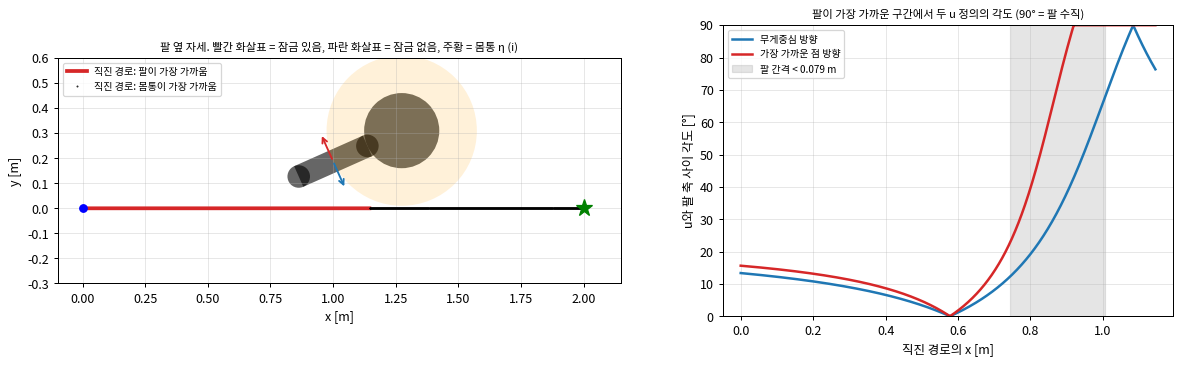

In [18]:
from common14.pose import ARM_LEN, M_ARM_PERP, pose_nearest, pose_nearest_point, pose_directional_eta_point, pose_cost_directional_point

SIDE_CY, SIDE_TILT = 0.31, 24.0                       # 몸통 중심 y [m], 팔과 경로 사이 각도 [°]
_t = np.radians(SIDE_TILT)
SIDE_DIR = (-np.cos(_t), -np.sin(_t))                 # 어깨 → 손: 왼쪽 아래
SIDE_C = (1.0 - make_pose((0.0, SIDE_CY), SIDE_DIR)['com'][1][0], SIDE_CY)      # 팔 무게중심이 x = 1.0에 오도록
# 로봇은 팔 아래(경로 쪽)에서 팔을 위(몸통 쪽)로 민다. 잠금 방향이 그쪽이면 '잠금 있음'
_sgn = +1 if ey @ make_pose(SIDE_C, SIDE_DIR, +1)['lock_dir'] > 0 else -1
LOCKS8 = {'잠금 있음': _sgn, '잠금 없음': -_sgn}
POSES8 = {k: make_pose(SIDE_C, SIDE_DIR, s, name=k) for k, s in LOCKS8.items()}
pz8 = POSES8['잠금 있음']
print('몸통 중심 (%.3f, %.3f) m, 어깨 %s, 손 %s, 팔과 경로 사이 각도 %.0f°' % (*SIDE_C, pz8['arm_a'].round(3), pz8['arm_b'].round(3), SIDE_TILT))
print('잠금 방향(이쪽으로 밀면 잠김): 잠금 있음 %s, 잠금 없음 %s' % (POSES8['잠금 있음']['lock_dir'].round(3), POSES8['잠금 없음']['lock_dir'].round(3)))
print('경로(y = 0) 위 로봇과 몸통의 간격 %.3f m (몸통 η, u = +y: (i) %.3f, (iii) %.3f, (ii) %.3f m)'
      % (SIDE_CY - S.TORSO_R - S.ROBOT_R, S.ETA0, eta_of_mass('iii', 1)(reduced_mass(directional_mass(ey, 'torso'))),
         eta_of_mass('ii', 1)(directional_mass(ey, 'torso'))))
tilt_min = np.degrees(np.arcsin((SIDE_CY - S.ARM_R - S.ROBOT_R - eta_L(1)) / (S.TORSO_R + ARM_LEN)))
print('팔을 경로와 나란하게(0°) 두면 팔 옆면-경로 간격 %.3f m. 팔 끝 간격이 팔 수직 자유 η %.3f m보다 작아지는 최소 각도 %.1f°'
      % (SIDE_CY - S.ARM_R - S.ROBOT_R, eta_L(1), tilt_min))

# 실행 전 확인: 직진 경로(y = 0)에서 가장 가까운 분절과 u의 각도
xs = np.linspace(S.START[0], S.GOAL[0], 2001)
PL = np.stack([xs, np.zeros_like(xs)], -1)
gl = pose_gaps(PL, pz8)
arm_sel = gl.argmin(-1) == 1
ang_of = lambda u: np.degrees(np.arccos(np.clip(np.abs(u @ pz8['axis']), 0, 1)))      # 0° = 팔 축, 90° = 팔 수직
_, _, u_com_l = pose_nearest(PL, pz8)
_, _, u_pt_l = pose_nearest_point(PL, pz8)
a_com_l, a_pt_l = ang_of(u_com_l), ang_of(u_pt_l)
ab9 = pz8['arm_b'] - pz8['arm_a']
s_l = np.clip((PL - pz8['arm_a']) @ ab9 / (ab9 @ ab9), 0, 1)                           # 팔 축 위 가장 가까운 점 (1 = 손 끝)
kl = int(np.argmin(gl[:, 1]))
print('\n직진 경로에서 가장 가까운 분절이 팔인 구간: x = %.3f ~ %.3f m (끊김 없음: %s, 경로의 %.0f%%)'
      % (xs[arm_sel].min(), xs[arm_sel].max(), bool(np.all(np.diff(np.nonzero(arm_sel)[0]) == 1)), 100 * arm_sel.mean()))
print('그 구간에서 팔의 가장 가까운 점이 손 끝(끝점)인 비율 %.2f, 옆면(안쪽 점)인 비율 %.2f'
      % ((s_l[arm_sel] >= 1).mean(), (s_l[arm_sel] < 1).mean()))
print('직진 경로의 팔 최소 간격 %.3f m (x = %.3f, 가장 가까운 점: %s), 몸통 최소 간격 %.3f m'
      % (gl[kl, 1], xs[kl], '손 끝' if s_l[kl] >= 1 else '옆면', gl[:, 0].min()))
ETA_ARM_MAX = float(eta_of_mass('iii', 1)(reduced_mass(4 * M_ARM_PERP)))              # (iii)의 팔 η 최댓값 (잠금 수직)
near_sel = arm_sel & (gl[:, 1] < ETA_ARM_MAX)
print('\nu와 팔 축 사이 각도 분포 [°] (최소 / 25% / 중앙 / 75% / 최대)')
for name, sel in [('팔이 가장 가까운 구간 전체', arm_sel), ('그중 팔 간격 < %.3f m' % ETA_ARM_MAX, near_sel)]:
    for dname, a in [('무게중심 방향', a_com_l), ('가장 가까운 점 방향', a_pt_l)]:
        print('  %-24s %-12s: %s' % (name, dname, ' / '.join('%.0f' % q for q in np.percentile(a[sel], [0, 25, 50, 75, 100]))))
print('직진 경로 최소 간격 지점의 각도: 무게중심 방향 %.0f°, 가장 가까운 점 방향 %.0f°' % (a_com_l[kl], a_pt_l[kl]))
for dname, u in [('무게중심', u_com_l[kl]), ('가장 가까운 점', u_pt_l[kl])]:
    for lk, p9 in POSES8.items():
        mh = float(pose_mass(u, 'arm', p9))
        print('  %-8s %-6s: m_h %.2f kg → (ii) η %.3f m | μ %.2f kg → (iii) η %.3f m'
              % (dname, lk, mh, eta_of_mass('ii', 1)(mh), reduced_mass(mh), eta_of_mass('iii', 1)(reduced_mass(mh))))

fig, axs = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axs[0]
draw_pose(ax, pz8, show_lock=False)
_m = pz8['com'][1]
ax.annotate('', xy=_m + 0.12 * POSES8['잠금 있음']['lock_dir'], xytext=_m, arrowprops=dict(arrowstyle='->', color='C3', lw=1.5))
ax.annotate('', xy=_m + 0.12 * POSES8['잠금 없음']['lock_dir'], xytext=_m, arrowprops=dict(arrowstyle='->', color='C0', lw=1.5))
ax.add_patch(plt.Circle(pz8['torso_c'], S.TORSO_R + S.ROBOT_R + S.ETA0, color='orange', alpha=0.15, lw=0))
ax.plot(xs[arm_sel], 0 * xs[arm_sel], 'C3', lw=3, label='직진 경로: 팔이 가장 가까움')
ax.plot(xs[~arm_sel], 0 * xs[~arm_sel], 'k.', ms=1, label='직진 경로: 몸통이 가장 가까움')
ax.plot(*S.START, 'bo'); ax.plot(*S.GOAL, 'g*', ms=14)
ax.set_aspect('equal'); ax.set_xlim(-0.1, 2.15); ax.set_ylim(-0.3, 0.6); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.legend(fontsize=8, loc='upper left')
ax.set_title('팔 옆 자세. 빨간 화살표 = 잠금 있음, 파란 화살표 = 잠금 없음, 주황 = 몸통 η (i)', fontsize=9)
ax = axs[1]
ax.plot(xs, np.where(arm_sel, a_com_l, np.nan), 'C0', lw=2, label='무게중심 방향')
ax.plot(xs, np.where(arm_sel, a_pt_l, np.nan), 'C3', lw=2, label='가장 가까운 점 방향')
ax.fill_between(xs, 0, 90, where=near_sel, color='gray', alpha=0.2, label='팔 간격 < %.3f m' % ETA_ARM_MAX)
ax.set_xlim(xs[arm_sel].min() - 0.05, xs[arm_sel].max() + 0.05); ax.set_ylim(0, 90)
ax.set_xlabel('직진 경로의 x [m]'); ax.set_ylabel('u와 팔 축 사이 각도 [°]')
ax.set_title('팔이 가장 가까운 구간에서 두 u 정의의 각도 (90° = 팔 수직)', fontsize=9); ax.legend(fontsize=8)
plt.show()

**실행 전 확인** (위 출력과 그림)
- 직진 경로에서 가장 가까운 분절이 팔인 구간은 x = 0~1.145 m(경로의 57%)이고 끊기지 않는다. 그 뒤로는 몸통이 가장 가깝다.
- 그 구간의 80%에서 팔의 가장 가까운 점은 손 끝이다. 직진 경로의 팔 최소 간격 0.032 m도 손 끝 바로 아래(x = 0.863)에서 생긴다. 기울어진 선분과 직선 사이에서 가장 가까운 점은 늘 선분의 한쪽 끝이다. 그래서 이 장면에서 로봇이 가장 가까이 지나는 곳은 팔 옆면 가운데가 아니라 **손 끝 쪽 옆면**이다.
- 팔 간격이 0.079 m((iii)의 팔 η 최댓값)보다 작은 구간에서 두 u 정의의 각도가 크게 다르다. 무게중심 방향은 12~68°(중앙 32°)로 팔 축 쪽에 가깝다. 가장 가까운 점 방향은 23~90°(중앙 71°)로 팔 수직에 가깝다. 오른쪽 그림의 회색 구간에서 두 곡선이 벌어지는 것이 이것이다.
- 직진 경로 최소 간격 지점의 각도는 무게중심 방향 30°, 가장 가까운 점 방향 66°다. 그래서 같은 위치에서 쓰이는 팔 질량이 정의에 따라 다르다. 무게중심 방향이면 잠금 있음 4.80 kg / 잠금 없음 1.20 kg, 가장 가까운 점 방향이면 9.02 / 2.25 kg이다. 팔 수직 질량(12 / 3 kg)에 가까운 것은 가장 가까운 점 방향이다.

**예측해 보기:** 8a는 기본 정의(무게중심 방향)로 돌린다. 로봇이 팔과 가장 가까울 때 쓰이는 질량은 팔 수직 쪽(3 / 12 kg)일까, 팔 길이 쪽(1 / 4 kg)일까?

### 8a. 잠금 방향 뒤집기

7a와 같은 방식이다. 로봇이 팔을 미는 방향(팔 아래에서 위, 몸통 쪽)에 잠금이 있는 경우와 없는 경우(잠금이 반대쪽)를 (i)·(ii)·(iii)으로 비교한다(p = 1, u는 기본 정의인 무게중심 방향, seed 16개). 측정은 7a와 같고, 팔과 가장 가까운 순간에 대해 다음을 더 적는다.
- 그 순간 가장 가까운 분절이 팔이었는지
- 그 순간 u와 팔 축 사이 각도, 쓰인 팔 질량 m_h와 η((i)은 η = 0.10 m 고정)

로봇이 실제로 팔을 피해 비켜 갔는지 보려고, 사람 비용 없이(목표 비용만) 돌린 경로의 팔 간격도 함께 적는다.

**예측해 보기:** 팔 수직 질량이 쓰인다면 (ii)의 잠금 있음/없음 η 차이는 0.169 − 0.042 m, (iii)은 0.079 − 0.042 m다. 이격 차이는 어느 쪽이 더 클까?

In [19]:
def close_stats(tr, pz, case, udef):
    # 팔과 가장 가까운 스텝에서: 가장 가까운 분절이 팔인지, 팔 방향 u와 팔 축 사이 각도, 팔 m_h, 그 m_h의 η
    k = int(np.argmin(pose_gaps(tr, pz)[:, 1]))
    p = tr[k]
    if udef == 'com':
        q = pz['com'][1]
    else:
        ab = pz['arm_b'] - pz['arm_a']
        q = pz['arm_a'] + np.clip((p - pz['arm_a']) @ ab / (ab @ ab), 0, 1) * ab
    u = (q - p) / np.linalg.norm(q - p)
    mh = float(pose_mass(u, 'arm', pz))
    eta_k = S.ETA0 if case == 'i' else float(eta_of_mass(case, 1)(reduced_mass(mh) if REDUCED[case] else mh))
    return dict(k=k, near_arm=bool(pose_gaps(p[None], pz)[0].argmin() == 1), ang=float(np.degrees(np.arccos(min(1.0, abs(u @ pz['axis']))))),
                m_close=mh, eta_close=eta_k, u_close=u)

def run_pose8(case, pz, seed, udef='com'):
    # udef: 'com' = 로봇 점 → 분절 무게중심 (기본), 'pt' = 로봇 점 → 분절 표면의 가장 가까운 점 (비교)
    if case == 'i':
        cost = partial(pose_cost_uniform, pose=pz)
        eta_fn = lambda P: pose_directional_eta(P, pz, pose_eta_fn('i'))
    else:
        cf, ef = (pose_cost_directional, pose_directional_eta) if udef == 'com' else (pose_cost_directional_point, pose_directional_eta_point)
        cost = partial(cf, pose=pz, eta_of_mass=eta_of_mass(case, 1), reduced=REDUCED[case])
        eta_fn = lambda P: ef(P, pz, eta_of_mass(case, 1), REDUCED[case])
    r = run_mpc(static_person, human_cost=cost, seed=seed, snapshot_steps=range(S.STEPS))
    tr = r['traj']
    arr = arrival_time(tr)
    n = S.STEPS if arr is None else int(round(arr / S.DT))             # 도달 전 스텝만 센다
    gap, eta, idx, _ = eta_fn(tr)
    plan = [eta_fn(r['snaps'][s]['plan'][1:])[:3] for s in range(n)]
    on = lambda g, e, i, seg: (i == seg) & (g < e)
    return dict(traj=tr, idx=idx, eta=eta, arm=pose_gaps(tr, pz)[:, 1].min(), length=path_length(tr), arrive=arr,
                on_arm=int(on(gap, eta, idx, 1)[:n].sum()), on_torso=int(on(gap, eta, idx, 0)[:n].sum()),
                plan_arm=float(np.mean([on(*q, 1).any() for q in plan])), plan_torso=float(np.mean([on(*q, 0).any() for q in plan])),
                arm_near=float((idx[:n] == 1).mean()), **close_stats(tr, pz, case, udef))

t0 = time.time()
RES8 = {(c, lk): [run_pose8(c, POSES8[lk], s) for s in SEEDS7] for c in ('i', 'ii', 'iii') for lk in LOCKS8}
FREE8 = [run_mpc(static_person, human_cost=lambda Pf, offs: np.zeros(Pf.shape[:-1]), seed=s)['traj'] for s in SEEDS7]
print('실행 시간 %.0f s' % (time.time() - t0))
print('(i)의 두 잠금 경우 궤적 최대 차이: %.1e m' % max(np.abs(a['traj'] - b['traj']).max() for a, b in zip(RES8[('i', '잠금 있음')], RES8[('i', '잠금 없음')])))
print('사람 비용 없이 돌린 경로의 팔 최소 간격: %s m, y 최솟값 %s m'
      % (rng_str([pose_gaps(tr, pz8)[:, 1].min() for tr in FREE8]), rng_str([tr[:, 1].min() for tr in FREE8])))

실행 시간 249 s
(i)의 두 잠금 경우 궤적 최대 차이: 0.0e+00 m
사람 비용 없이 돌린 경로의 팔 최소 간격: -0.007~0.070 m, y 최솟값 -0.054~-0.018 m


In [20]:
def mean_rng(vals, fmt='%.3f'):
    return '%s (%s)' % (rng_str(vals, fmt), fmt % np.mean(vals))

print('[팔과 가장 가까운 순간]')
print('%-6s %-6s | %-22s | %-9s | %-11s | %-11s | %-13s' % ('경우', '잠금', '팔 최소 이격 (평균)', '팔이 가장 가까움', '각도 [°]', 'm_h [kg]', 'η [m]'))
for c in ('i', 'ii', 'iii'):
    for lk in LOCKS8:
        rs = RES8[(c, lk)]
        print('%-6s %-6s | %-22s | %2d / %-5d | %-11s | %-11s | %-13s' % ('(%s)' % c, lk, mean_rng([r['arm'] for r in rs]), sum(r['near_arm'] for r in rs), len(rs),
              rng_str([r['ang'] for r in rs], '%.0f'), rng_str([r['m_close'] for r in rs], '%.2f'), rng_str([r['eta_close'] for r in rs])))
print('\n[비용과 경로]')
print('%-6s %-6s | %-9s | %-11s | %-17s | %-10s | %-15s | %s' % ('경우', '잠금', '팔 비용 스텝', '계획 팔 비용', '몸통 비용 실행/계획', '경로 길이', '도달 [s]', '팔이 가장 가까운 스텝 비율'))
for c in ('i', 'ii', 'iii'):
    for lk in LOCKS8:
        rs = RES8[(c, lk)]
        print('%-6s %-6s | %-9s | %-11s | %-17s | %-10s | %-15s | %s' % ('(%s)' % c, lk, rng_str([r['on_arm'] for r in rs], '%d'), rng_str([r['plan_arm'] for r in rs], '%.2f'),
              rng_str([r['on_torso'] for r in rs], '%d') + ' / ' + rng_str([r['plan_torso'] for r in rs], '%.2f'), rng_str([r['length'] for r in rs], '%.2f'),
              rng_str([r['arrive'] for r in rs], '%.2f') + (' 못 함 %d' % sum(r['arrive'] is None for r in rs) if any(r['arrive'] is None for r in rs) else ''),
              rng_str([r['arm_near'] for r in rs], '%.2f')))
print()
for c in ('i', 'ii', 'iii'):
    d = np.mean([r['arm'] for r in RES8[(c, '잠금 있음')]]) - np.mean([r['arm'] for r in RES8[(c, '잠금 없음')]])
    eh = np.mean([r['eta_close'] for r in RES8[(c, '잠금 있음')]]) - np.mean([r['eta_close'] for r in RES8[(c, '잠금 없음')]])
    print('(%-3s) 팔 최소 이격 평균 차이 (잠금 있음 − 없음): %+.4f m, 그 순간 η 평균 차이 %+.4f m' % (c, d, eh))

[팔과 가장 가까운 순간]
경우     잠금     | 팔 최소 이격 (평균)           | 팔이 가장 가까움 | 각도 [°]      | m_h [kg]    | η [m]        
(i)    잠금 있음  | 0.100~0.137 (0.121)    | 16 / 16    | 36~43       | 5.22~5.80   | 0.100~0.100  
(i)    잠금 없음  | 0.100~0.137 (0.121)    | 16 / 16    | 36~43       | 1.31~1.45   | 0.100~0.100  
(ii)   잠금 있음  | 0.270~0.337 (0.301)    | 16 / 16    | 33~40       | 4.96~5.53   | 0.070~0.078  
(ii)   잠금 없음  | 0.272~0.337 (0.302)    | 16 / 16    | 33~40       | 1.25~1.38   | 0.018~0.019  
(iii)  잠금 있음  | 0.067~0.121 (0.097)    | 16 / 16    | 33~42       | 4.97~5.68   | 0.056~0.060  
(iii)  잠금 없음  | 0.056~0.116 (0.087)    | 16 / 16    | 32~41       | 1.23~1.40   | 0.022~0.025  

[비용과 경로]
경우     잠금     | 팔 비용 스텝   | 계획 팔 비용     | 몸통 비용 실행/계획       | 경로 길이      | 도달 [s]          | 팔이 가장 가까운 스텝 비율
(i)    잠금 있음  | 0~0       | 0.00~0.07   | 0~0 / 0.00~0.00   | 2.25~2.43  | 1.45~2.30       | 0.37~0.59
(i)    잠금 없음  | 0~0       | 0.00~0.07   | 0~0 / 0.00~0.00   | 2.25~2.43  | 1.45~2.30       |

**결과 해석** (표를 보며)
- **로봇은 팔을 피해 비켜 갔다.** 사람 비용 없이 돌리면 팔 최소 간격이 −0.007~0.070 m(팔과 겹친 실행도 있음)다. (i)·(iii)에서는 0.056~0.137 m로 벌어졌다.
- **팔 비용은 실행 경로와 평균 계획에서 거의 켜지지 않았다.** 팔 비용 스텝은 모든 경우 0이다. 계획에서도 (ii)·(iii)은 0, (i)은 0~7%다. 로봇은 팔 η보다 바깥을 지나갔다((iii) 이격 0.056~0.121 m, 그때 η 0.022~0.060 m). 7a와 같은 모습이며, η 바깥을 지나간 이유(샘플 잡음의 여유 등)는 이 노트에서 나누어 확인하지 않았다.
- **기본 정의에서는 팔 수직 질량이 쓰이지 않았다.** 가장 가까운 순간 u와 팔 축 사이 각도는 32~43°다. 쓰인 질량은 잠금 있음 4.96~5.80 kg, 잠금 없음 1.23~1.45 kg으로, 팔 수직(12 / 3 kg)보다 팔 길이 방향(4 / 1 kg)에 가깝다. 로봇이 손 끝 아래를 지나는 순간 팔 무게중심이 팔 축을 따라 0.15 m 안쪽에 있기 때문이다.
- **(i)은 잠금과 무관하다:** 나왔다. 두 경우의 궤적이 완전히 같다.
- **잠금 쪽을 밀 때 이격이 더 크다:** (iii)에서 방향은 나왔다. 평균 0.097 vs 0.087 m로 +1.00 cm지만, seed 범위는 겹친다(0.067~0.121 vs 0.056~0.116 m). 그 순간 η 차이(+3.5 cm)보다 훨씬 작고, 7a(+0.95 cm)와 거의 같다.
- **차이는 (ii)가 (iii)보다 크다:** 이 장면에서는 확인할 수 없다. 이유: 가벼운 쪽에 기준을 맞춰 (ii)의 몸통 η가 0.45 m가 되었고, 그래서 몸통이 경로를 정했다. (ii)의 잠금 효과는 −0.09 cm로 없다. (ii)에서는 몸통 η(0.45 m) 때문에 몸통 비용이 켜졌다(실행 3~4스텝, 계획 21~47%). 그래서 경로가 y ≈ −0.3 m까지 내려갔다. 팔 이격이 0.27~0.34 m로 팔 η(0.018~0.078 m)보다 훨씬 커서 팔 잠금이 경로에 영향을 줄 수 없었다. 도달 시간도 2.15~3.55 s로 늦다.

### 그림 — 8a 대표 경로

seed 0의 경로를 잠금 여부별로 겹쳐 그린다(실선 = 잠금 있음, 점선 = 잠금 없음). 점의 색은 그 위치에서 비용에 쓰인 η, 모양은 가장 가까운 분절(동그라미 = 팔, 네모 = 몸통)이다. 빨간 화살표는 "잠금 있음"의 잠금 방향, 파란 화살표는 "잠금 없음"의 잠금 방향이다.

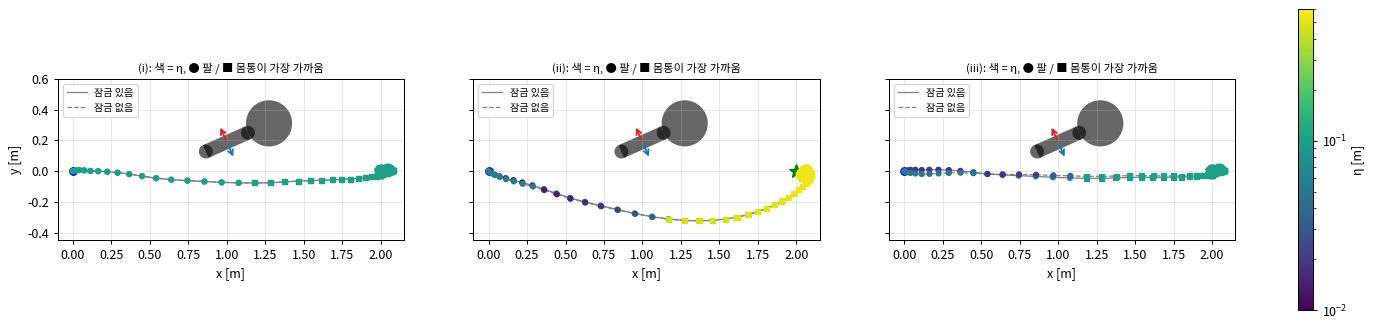

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
norm = LogNorm(0.01, 0.6)
for ax, c in zip(axs, ['i', 'ii', 'iii']):
    draw_pose(ax, pz8, show_lock=False)
    m = pz8['com'][1]
    ax.annotate('', xy=m + 0.12 * POSES8['잠금 있음']['lock_dir'], xytext=m, arrowprops=dict(arrowstyle='->', color='C3', lw=1.5))
    ax.annotate('', xy=m + 0.12 * POSES8['잠금 없음']['lock_dir'], xytext=m, arrowprops=dict(arrowstyle='->', color='C0', lw=1.5))
    for lk, ls in [('잠금 있음', '-'), ('잠금 없음', '--')]:
        r = RES8[(c, lk)][0]
        tr = r['traj']
        ax.plot(*tr.T, ls, color='gray', lw=1, label=lk)
        for seg, mk in [(1, 'o'), (0, 's')]:
            sel = r['idx'] == seg
            sc = ax.scatter(tr[sel, 0], tr[sel, 1], c=r['eta'][sel], cmap='viridis', norm=norm, s=16, marker=mk, zorder=3)
    ax.plot(*S.START, 'bo'); ax.plot(*S.GOAL, 'g*', ms=12)
    ax.set_aspect('equal'); ax.set_xlim(-0.1, 2.15); ax.set_ylim(-0.45, 0.6); ax.set_xlabel('x [m]')
    ax.set_title(f'{label(c, 1)}: 색 = η, ● 팔 / ■ 몸통이 가장 가까움', fontsize=9); ax.legend(fontsize=8, loc='upper left')
axs[0].set_ylabel('y [m]')
fig.colorbar(sc, ax=axs, fraction=0.012, label='η [m]')
plt.show()

**그림:** (i)·(iii)은 경로가 팔 아래에서 조금 내려갔다가 몸통 옆을 지나 다시 올라온다. 잠금 있음(실선)과 없음(점선)이 거의 겹친다. (iii)에서 팔이 가장 가까운 앞부분(동그라미)은 색이 어둡다(η가 작음). (ii)는 몸통이 가장 가까운 구간(네모)의 η가 커서(노란색) 아래로 크게 돌아간다.

### 8b. u 정의 비교

같은 장면에서 8a의 (iii)을 u 정의 두 가지로 돌린다.
- **기존:** 로봇 점 → 가장 가까운 분절 무게중심 (8a의 결과를 그대로 쓴다)
- **비교:** 로봇 점 → 가장 가까운 분절 표면의 가장 가까운 점. 몸통(원)에서는 두 정의가 같고, 팔(캡슐)에서는 팔 축 선분의 가장 가까운 점 방향이 된다.

7절 장면(팔 뻗은 자세, 팔 끝을 돌아감)에서도 (iii)을 두 정의로 돌린다. 기존 정의는 7a의 결과를 그대로 쓴다. 측정은 8a와 같다.

In [22]:
t0 = time.time()
RES8B = {('팔 옆', 'pt', lk): [run_pose8('iii', POSES8[lk], s, 'pt') for s in SEEDS7] for lk in LOCKS8}
RES8B.update({('팔 옆', 'com', lk): RES8[('iii', lk)] for lk in LOCKS8})
RES8B.update({('팔 뻗은', 'pt', lk): [run_pose8('iii', POSES[lk], s, 'pt') for s in SEEDS7] for lk in LOCKS})
RES8B.update({('팔 뻗은', 'com', lk): [dict(r, **close_stats(r['traj'], POSES[lk], 'iii', 'com')) for r in RES7[('iii', lk)]] for lk in LOCKS})
print('실행 시간 %.0f s\n' % (time.time() - t0))

UDEF = {'com': '무게중심', 'pt': '가장 가까운 점'}
print('%-6s %-6s %-8s | %-22s | %-9s | %-9s | %-11s | %-12s | %-8s | %-10s | %-10s | %s' % ('장면', '잠금', 'u 정의', '팔 최소 이격 (평균)', '각도 [°]', 'm_h [kg]',
      'η [m]', '팔 비용 스텝', '계획', '경로 길이', '도달 [s]', '팔이 가장 가까움'))
for scene, locks in [('팔 옆', LOCKS8), ('팔 뻗은', LOCKS)]:
    for lk in locks:
        for ud in ('com', 'pt'):
            rs = RES8B[(scene, ud, lk)]
            print('%-6s %-6s %-8s | %-22s | %-9s | %-9s | %-11s | %-12s | %-8s | %-10s | %-10s | %d / %d' % (scene, lk, UDEF[ud], mean_rng([r['arm'] for r in rs]),
                  rng_str([r['ang'] for r in rs], '%.0f'), rng_str([r['m_close'] for r in rs], '%.2f'), rng_str([r['eta_close'] for r in rs]),
                  rng_str([r['on_arm'] for r in rs], '%d'), rng_str([r['plan_arm'] for r in rs], '%.2f'), rng_str([r['length'] for r in rs], '%.2f'),
                  rng_str([r['arrive'] for r in rs], '%.2f'), sum(r['near_arm'] for r in rs), len(rs)))
    print()
for scene, locks in [('팔 옆', list(LOCKS8)), ('팔 뻗은', list(LOCKS))]:
    mean_arm = lambda ud, lk: np.mean([r['arm'] for r in RES8B[(scene, ud, lk)]])
    for ud in ('com', 'pt'):
        print('%-6s %-8s: 잠금 효과 (%s − %s) 팔 최소 이격 평균 %+.4f m' % (scene, UDEF[ud], locks[0], locks[1], mean_arm(ud, locks[0]) - mean_arm(ud, locks[1])))
    for lk in locks:
        dtr = max(np.abs(a['traj'] - b['traj']).max() for a, b in zip(RES8B[(scene, 'com', lk)], RES8B[(scene, 'pt', lk)]))
        print('%-6s %-6s: 정의 차이 (가장 가까운 점 − 무게중심) 팔 최소 이격 평균 %+.4f m, 각도 평균 %+.0f°, 같은 seed 궤적 최대 차이 %.3f m'
              % (scene, lk, mean_arm('pt', lk) - mean_arm('com', lk),
                 np.mean([r['ang'] for r in RES8B[(scene, 'pt', lk)]]) - np.mean([r['ang'] for r in RES8B[(scene, 'com', lk)]]), dtr))

실행 시간 117 s

장면     잠금     u 정의     | 팔 최소 이격 (평균)           | 각도 [°]    | m_h [kg]  | η [m]       | 팔 비용 스텝      | 계획       | 경로 길이      | 도달 [s]     | 팔이 가장 가까움
팔 옆    잠금 있음  무게중심     | 0.067~0.121 (0.097)    | 33~42     | 4.97~5.68 | 0.056~0.060 | 0~0          | 0.00~0.00 | 2.24~2.43  | 1.45~2.30  | 16 / 16
팔 옆    잠금 있음  가장 가까운 점 | 0.078~0.126 (0.105)    | 61~71     | 8.21~9.84 | 0.070~0.075 | 0~0          | 0.00~0.00 | 2.24~2.43  | 1.45~2.30  | 16 / 16
팔 옆    잠금 없음  무게중심     | 0.056~0.116 (0.087)    | 32~41     | 1.23~1.40 | 0.022~0.025 | 0~0          | 0.00~0.00 | 2.24~2.43  | 1.45~2.30  | 16 / 16
팔 옆    잠금 없음  가장 가까운 점 | 0.061~0.116 (0.091)    | 61~71     | 2.03~2.50 | 0.032~0.037 | 0~0          | 0.00~0.00 | 2.24~2.43  | 1.45~2.30  | 16 / 16

팔 뻗은   다가오는 쪽 무게중심     | 0.041~0.058 (0.051)    | 2~11      | 1.03~4.06 | 0.019~0.050 | 0~1          | 0.00~0.19 | 2.31~2.49  | 1.45~2.30  | 16 / 16
팔 뻗은   다가오는 쪽 가장 가까운 점 | 0.043~0.059 (0.052)    | 3~24      | 1.12~4.31 | 0.021~0.052 | 0~1

**결과 해석**
- **팔 옆 자세에서는 정의에 따라 쓰이는 질량이 크게 다르다.** 가장 가까운 순간의 각도는 무게중심 방향 32~42°, 가장 가까운 점 방향 61~71°다. 쓰인 m_h는 잠금 있음에서 4.97~5.68 → 8.21~9.84 kg, 잠금 없음에서 1.23~1.40 → 2.03~2.50 kg이다. 가장 가까운 점 정의에서는 팔 수직 질량(12 / 3 kg)에 가까운 값이 쓰인다. η도 잠금 있음 0.056~0.060 → 0.070~0.075 m, 잠금 없음 0.022~0.025 → 0.032~0.037 m로 커진다.
- **하지만 행동 차이는 작다.** 가장 가까운 점 정의에서 팔 최소 이격 평균이 잠금 있음 +0.73 cm, 잠금 없음 +0.36 cm 커졌다. 같은 seed 궤적의 차이는 최대 1.1 cm다. 잠금 효과(있음 − 없음)는 무게중심 +1.00 cm, 가장 가까운 점 +1.36 cm이고, seed 범위는 겹친다. 경로 길이와 도달 시간은 같고, 두 정의 모두 팔 비용이 실행·계획에서 켜지지 않았다.
- **팔 뻗은 자세(7절)에서는 두 정의의 차이가 작다:** 확인됐다. 각도는 무게중심 2~11°, 가장 가까운 점 3~24°로 둘 다 팔 축에 가깝다. 질량과 η 범위도 거의 같다. 팔 최소 이격 평균 차이는 +0.12 cm(다가오는 쪽 잠금), +0.22 cm(지나간 쪽 잠금)이고, 잠금 효과는 +0.95 vs +0.85 cm다. 팔 끝을 돌아갈 때는 무게중심과 가장 가까운 점(손 끝)이 모두 로봇에서 본 팔 축 위에 있어 두 u가 비슷하다.

### 그림 — 같은 순간의 두 u

기존 정의로 돌린 (iii) seed 0 경로(잠금 있음 / 다가오는 쪽 잠금)에서, 팔과 가장 가까운 순간 로봇 위치에 두 u를 함께 그린다(파랑 = 무게중심 방향, 빨강 = 가장 가까운 점 방향). 옅은 화살표는 그 전후 몇 스텝의 두 u다.

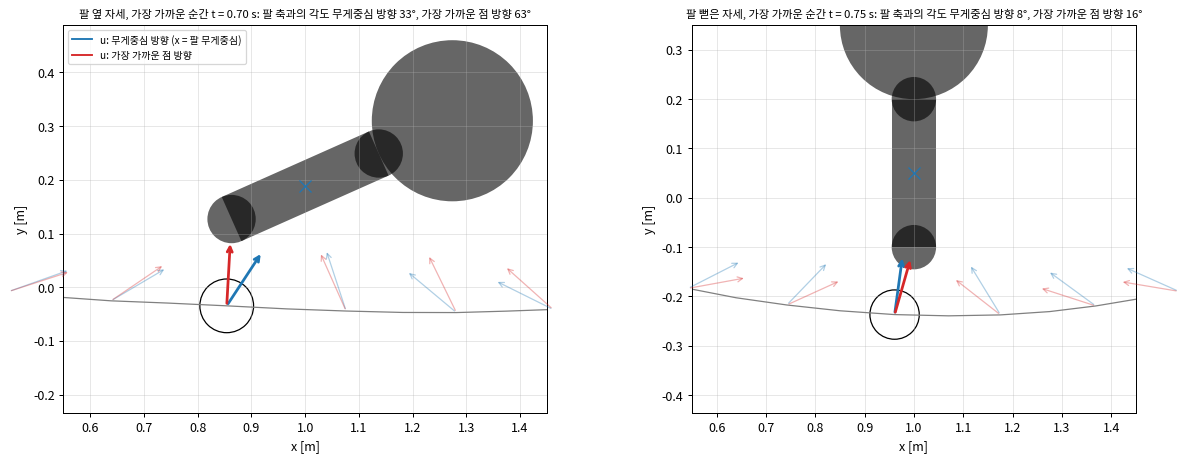

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.6))
for ax, (scene, pz, lk) in zip(axs, [('팔 옆', pz8, '잠금 있음'), ('팔 뻗은', POSES['다가오는 쪽'], '다가오는 쪽')]):
    r = RES8B[(scene, 'com', lk)][0]
    tr, k = r['traj'], r['k']
    draw_pose(ax, pz, show_lock=False)
    ax.plot(*tr.T, color='gray', lw=1)
    ab = pz['arm_b'] - pz['arm_a']
    for j, alpha, lw in [(j, 0.35, 1.0) for j in range(max(0, k - 8), min(len(tr), k + 9), 2) if j != k] + [(k, 1.0, 2.2)]:
        p = tr[j]
        q_pt = pz['arm_a'] + np.clip((p - pz['arm_a']) @ ab / (ab @ ab), 0, 1) * ab
        for q, col in [(pz['com'][1], 'C0'), (q_pt, 'C3')]:
            u = (q - p) / np.linalg.norm(q - p)
            ax.annotate('', xy=p + 0.12 * u, xytext=p, arrowprops=dict(arrowstyle='->', color=col, lw=lw, alpha=alpha))
    ax.add_patch(plt.Circle(tr[k], S.ROBOT_R, fill=False, color='k', lw=1))
    ax.plot(*pz['com'][1], 'C0x', ms=9)
    q_pt = pz['arm_a'] + np.clip((tr[k] - pz['arm_a']) @ ab / (ab @ ab), 0, 1) * ab
    a_pt = np.degrees(np.arccos(min(1.0, abs((q_pt - tr[k]) @ pz['axis']) / np.linalg.norm(q_pt - tr[k]))))
    c0 = pz['com'][1]
    ax.set_aspect('equal'); ax.set_xlim(c0[0] - 0.45, c0[0] + 0.45); ax.set_ylim(min(tr[k, 1], c0[1]) - 0.2, c0[1] + 0.3)
    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
    ax.set_title('%s 자세, 가장 가까운 순간 t = %.2f s: 팔 축과의 각도 무게중심 방향 %.0f°, 가장 가까운 점 방향 %.0f°'
                 % (scene, k * S.DT, r['ang'], a_pt), fontsize=9)
axs[0].plot([], [], 'C0', label='u: 무게중심 방향 (x = 팔 무게중심)'); axs[0].plot([], [], 'C3', label='u: 가장 가까운 점 방향')
axs[0].legend(fontsize=8, loc='upper left')
plt.show()

**그림:** 왼쪽(팔 옆)에서는 가장 가까운 순간 두 화살표가 팔 축 기준 33° vs 63°로 벌어진다. 빨강(가장 가까운 점)은 손 끝을 향해 거의 위(팔 수직 쪽)를 가리킨다. 파랑(무게중심)은 팔 안쪽 무게중심을 향해 오른쪽으로 기운다. 오른쪽(팔 뻗은)에서는 8° vs 16°로 두 화살표가 모두 팔 축(위)을 향한다.

### 8절에서 본 것

| 가설·질문 | 결과 |
|---|---|
| 8a: (i)은 잠금과 무관 | **나옴.** 궤적이 완전히 같다 |
| 8a: 팔 옆을 지나면 팔 수직 질량이 쓰인다 | **기본 정의(무게중심)에서는 안 나옴.** 각도 32~43°, 질량 1.2~1.5 / 5.0~5.8 kg(팔 길이 방향에 가까움) |
| 8a: 잠금 쪽을 밀 때 이격이 더 크다 | **(iii)은 방향만 나옴.** +1.00 cm, seed 범위 겹침. **(ii)는 안 나옴**(−0.09 cm): 몸통 비용이 경로를 정해 팔과 멀었다 |
| 8a: 그 차이는 (ii)가 (iii)보다 크다 | **이 장면에서는 확인할 수 없음.** 가벼운 쪽에 기준을 맞춰 (ii)의 몸통 η가 0.45 m가 되어 몸통이 경로를 정했다 |
| 8b: u 정의에 따라 쓰이는 질량 | **팔 옆에서 크게 다름.** 가장 가까운 점 방향은 각도 61~71°, 질량 2.0~2.5 / 8.2~9.8 kg로 팔 수직에 가깝다. 이격 차이는 +0.4~0.7 cm |
| 8b: 팔 끝을 돌 때 두 정의 차이가 작다 | **나옴.** 각도 2~11° vs 3~24°, 이격 차이 0.1~0.2 cm |

연구의 충돌 방향 정의에 대해 다음을 볼 수 있다. 무게중심 방향 정의에서는 로봇이 긴 분절의 끝 쪽에 있을 때 u가 분절 축 쪽으로 기운다. 그래서 그 분절의 수직 질량(ROM 잠금의 주 대상)이 덜 쓰인다. 가장 가까운 점 정의는 이 장면에서 수직에 가까운 질량을 썼지만, 이격 차이는 1 cm 미만이었다. 정지한 사람, 가장 가까운 분절 하나만 보는 비용, 팔 η 1~8 cm인 이 노트의 조건에서는 두 정의가 행동을 거의 바꾸지 않았다. 정의 선택의 차이는 주로 "어느 질량을 쓰는가"에서 드러났다.

## 9. 정리

| 가설 | 결과 |
|---|---|
| (i)에서는 위아래 선택이 거의 반반 | **나옴.** 위 14 / 아래 18 |
| (ii)(iii)에서 가벼운 쪽(위)으로 지나가는 비율이 높다 | **(iii)은 안 나옴.** (i)과 같은 14 / 18, 같은 seed에서 30 / 32가 (i)과 같은 쪽. **(ii)는 23 / 9로 위가 많지만**, ROM 잠금을 빼도 22 / 10이라 질량 방향 선호가 아니다 |
| (iii)은 (ii)보다 쪽별 이격 차이가 작다 | **비교 불가.** 두 경우 모두 쪽별 차이가 없었다 |
| 무거운 쪽을 지날 때 이격이 더 크다 | **안 나옴.** 팔과의 이격 범위가 위아래에서 겹친다 |
| 환산질량이 대비를 압축한다 | **수치로 확인.** 팔 잠금/자유 4 → 1.88배, 몸통/팔 자유 13.3 → 2.37배 |
| 7a: (i)은 잠금 방향과 무관 | **나옴.** 궤적이 완전히 같다 |
| 7a: 잠금 쪽을 밀 때 이격이 더 크다 | **방향은 나옴, 차이는 작음.** 평균 +1 cm, seed 범위 겹침 |
| 7a: (iii)의 차이가 (ii)보다 작다 | **안 나옴.** +0.95 vs +1.00 cm. 쓰인 질량이 팔 길이 방향이라 대비가 4배 vs 1.88배가 아니었다 |
| 7b: 쪽 선택 | **진행하지 않음.** 팔 끝 쪽으로만 지나갈 수 있는 기하(96개 실행 모두 팔 끝 아래) |
| 8a: 팔 옆을 지날 때 잠금 쪽 이격이 더 크다 | **(iii)은 방향만 나옴**(+1.00 cm, seed 범위 겹침). **(ii)는 이 장면에서 확인할 수 없음**: 가벼운 쪽에 기준을 맞춰 몸통 η가 0.45 m가 되어 몸통이 경로를 정했다 |
| 8b: u 정의(무게중심 vs 가장 가까운 점) | **쓰이는 질량은 팔 옆에서 크게 다르고**(각도 32~42° vs 61~71°), **이격 차이는 1 cm 미만.** 팔 끝을 돌 때는 차이가 작다 |

방향 효과가 나오지 않은 직접 원인은 팔의 비용이 한 번도 켜지지 않은 것이다(5절). 팔이 기준 자세에서 몸통 비용 영역의 그늘에 있기 때문이다. 가장 가까운 분절 하나만 보는 비용에서는 몸통 그늘 안의 가벼운 분절(팔)의 방향별 질량이 행동에 나타나지 않는다. 이 방식의 한계는 18에서 쌍별 합산과 비교한다.

**팔이 그늘 밖에 있을 때(7절):** 팔이 경로를 막는 자세에서는 팔이 가장 가까운 분절이 되었고, 잠금 쪽을 밀 때 팔과의 이격이 평균 약 1 cm 컸다((ii) +1.00, (iii) +0.95 cm, seed 범위는 겹침). 하지만 로봇이 팔 끝을 돌아가므로 쓰이는 질량은 팔 길이 방향(1 ↔ 4 kg)이었고, (iii)의 차이가 (ii)보다 작다는 가설은 나오지 않았다. 팔 비용이 켜진 스텝도 실행 0~1, 계획 0~20%로 매우 적었다. 다른 자세 4개에서도 같았다.

**팔 옆을 지날 때(8절):** 로봇이 팔 끝을 돌지 않고 팔 아래를 따라 지나가도, 기본 정의(무게중심 방향)에서 가장 가까운 순간의 u는 팔 축에서 32~43°라 팔 수직 질량이 쓰이지 않았다. 가장 가까운 점 방향으로 정의하면 61~71°로 팔 수직에 가까운 질량이 쓰였지만, 팔 이격은 1 cm 미만으로 바뀌었다.

**방향별 질량이 행동에 잘 드러나지 않은 원인**

| 원인 | 근거가 된 절 | 다룰 노트 |
|---|---|---|
| (1) 가장 가까운 분절 하나만 보는 비용에서 생기는 몸통 그늘 | 5절(기준 자세에서 팔 비용이 켜진 실행 0 / 32, 잠금을 빼도 쪽 선택이 같음), 8a의 (ii)(몸통 η가 경로를 정함) | 18 (쌍별 합산과 비교) |
| (2) 무게중심 방향 u가 긴 분절에서 팔 축 쪽으로 기울어짐 | 7절(가장 가까운 순간 팔 축과 2~11°), 8a·8b(팔 옆에서도 32~43°, 가장 가까운 점 방향은 61~71°) | 결정 3 재검토 (충돌 방향 u 정의) |
| (3) η 규모(수 cm)가 MPPI 잡음 편향과 비슷함 | 7a·8a(η 차이 3~4 cm가 이격 차이 약 1 cm로 줄고 seed 범위가 겹침), 8b(정의를 바꿔 η가 1~1.5 cm 커져도 이격은 0.4~0.7 cm), 15(잡음 편향 1~2.4 cm) | 17 (해상도), 19 (필요 이격 거리) |

**연구의 조합 1 결정에 쓸 수 있는 관찰**
- 방향별 η가 경로에 영향을 주려면, 그 방향의 비용이 켜지는 거리까지 경로가 들어가야 한다. 분절 하나의 방향 비대칭은 더 큰 η를 가진 이웃 분절의 그늘에 있으면 효과가 없다.
- 사람 쪽 유효질량 m_h를 그대로 쓰면((ii)), 가벼운 쪽에 기준을 맞출 때 몸통 η가 0.45~0.56 m로 커져 목표 도달을 막았다. 환산질량((iii))은 대비를 압축해 이 문제가 없다.
- 팔이 경로를 막는 자세(7절)에서는 방향별 η가 이격을 바꿨지만(약 1 cm), 팔 끝을 돌아가는 경로에서 u가 팔 길이 방향이라 쓰인 것은 길이 방향 질량이었다. 팔 옆을 지나는 자세(8절)에서도 무게중심 방향 u로는 팔 수직 질량(ROM 잠금 4배의 주된 대상)이 쓰이지 않았다. 가장 가까운 점 방향 u로는 쓰였지만, 이격 차이는 1 cm 미만이었다. 무게중심 방향 정의를 유지하면, 긴 분절 끝 쪽에서는 수직 질량 대신 축 쪽 질량이 쓰인다는 점을 알고 써야 한다.
- 이 노트는 정지한 사람, 기준 자세 seed 32개, 팔 뻗은 자세와 팔 옆 자세 각각 seed 16개의 결과다.

u 정의는 가장 가까운 점 방향이 접촉 법선에 더 가깝다. 행동 차이는 현재 η 규모에서 약 1 cm이며, 19 이후 다시 판단한다.

## 핵심 정리

- 같은 분절이라도 충돌 방향 u에 따라 유효질량이 다르다(팔: 길이 1 kg, 수직 3 kg, ROM 잠금 쪽 4배).
- 방향별 η(u) = η_L (m(u)/m_L)^p. m으로 m_h를 쓰면 대비가 그대로, μ를 쓰면 압축된다(μ는 m_r을 넘지 못함).
- 방향별 η는 쪽 선택과 이격을 정할 수 있지만, 그 분절의 비용이 경로에서 켜질 때만이다. 기준 자세에서 팔은 몸통의 그늘에 있어 방향 효과가 나오지 않았다.
- 팔이 경로를 막으면 잠금 쪽을 밀 때 이격이 조금(약 1 cm) 커진다. 단, 팔 끝을 돌아갈 때 u는 팔 길이 방향이라 길이 방향 질량이 쓰인다.
- u를 무게중심 방향으로 정의하면, 로봇이 긴 분절 끝 쪽에 있을 때 u가 축 쪽으로 기울어 수직 질량이 덜 쓰인다. 가장 가까운 점 방향은 수직에 가깝지만, 이 노트의 장면에서 이격 차이는 1 cm 미만이었다.
- 가장 가까운 분절이 바뀌는 곳과 ROM 경계에서 η가 뛴다. 이 노트에서는 명령 변화량에 큰 차이를 만들지 않았다(18에서 다룸).

## 확인 문제

<details><summary>1. (계산) m_h = 12 kg, m_r = 5 kg이면 μ는? m_h = 3 kg이면? 두 μ의 비는 m_h 비(4배)와 비교해 어떤가?</summary>

60/17 = **3.53 kg**, 15/8 = **1.875 kg**. 비 3.53/1.875 = **1.88배**로 4배보다 작다(대비 압축).
</details>

<details><summary>2. (보기) 로봇이 팔을 아래에서 위로 밀 때(u = +y)와 위에서 아래로 밀 때(u = −y), (ii)·(iii)에서 η가 큰 쪽은? (a) 아래에서 위로 (b) 위에서 아래로 (c) 같다</summary>

**(a)**. u·n > 0이라 ROM 잠금 쪽이고 질량이 4배(μ로 1.88배)다.
</details>

<details><summary>3. (계산) η_L = 0.04 m(3 kg, 자유 쪽), p = 1일 때 잠금 쪽(12 kg) η는 (ii)에서 몇 m인가? (iii)에서는(μ 1.875 → 3.53 kg)?</summary>

(ii) 0.04 × 12/3 = **0.16 m**. (iii) 0.04 × 3.53/1.875 = **0.075 m**.
</details>

<details><summary>4. (보기) 질량이 위아래 모두 같은 몸통(m_h 40 kg)과 팔 자유 쪽(3 kg)의 대비를 μ로 바꾸면? (a) 13.3배 그대로 (b) 약 2.4배로 줄어든다 (c) 1배가 된다</summary>

**(b)**. 4.44 / 1.875 ≈ 2.37배.
</details>

<details><summary>5. (보기) 이 장면에서 방향별 η가 쪽 선택을 바꾸지 못한 직접 원인은? (a) seed가 적어서 (b) 경로가 팔의 η 영역 안으로 들어가지 않아 팔 비용이 켜지지 않았다 (c) w = 100이 작아서</summary>

**(b)**. 팔 비용이 켜진 실행이 0 / 32였고, 잠금을 빼도 쪽 선택이 같았다.
</details>

<details><summary>6. (계산) 팔 축이 (0, 0)에서 (0.3, 0)까지이고 무게중심은 (0.15, 0)이다. 로봇 점이 (0.25, −0.10)에 있을 때, 무게중심 방향 u와 가장 가까운 점 방향 u 사이 각도는? 팔 m_h(자유, 길이 1 kg / 수직 3 kg)는 각 정의에서 몇 kg인가?</summary>

가장 가까운 점은 (0.25, 0)이라 그 방향은 (0, 1)이다. 팔 수직이라 m_h = **3 kg**.
무게중심 방향은 (−0.10, 0.10)/‖·‖로 팔 축과 45°다. 두 u 사이 각도는 **45°**다.
무게중심 방향의 m_h = 1/(cos²45°/1 + sin²45°/3) = 1/(0.5 + 0.167) = **1.5 kg**.
</details>

## 다음 노트

**[17 · MPPI는 비용 차이를 얼마나 세밀하게 행동으로 옮기는가](17_ess.ipynb)**: 샘플 잡음 σ, 온도 β, 후보 수 K가 유효 샘플 수(ESS), 잡음 편향, 그리고 수 cm의 η 차이가 이격 차이로 구별되는지를 어떻게 바꾸는지 본다. 15의 σ = 0.25 예외도 다시 확인한다.